# Dự đoán giá ô tô: Ridge Regression và Random Forest

**Bài toán:** hồi quy có giám sát, dự đoán **giá rao bán (triệu đồng)** của ô tô cũ và mới trên Chợ Tốt từ các đặc trưng của xe.

**Dữ liệu:** `clean_data_oto.csv`, kết quả của `preprocess_data.ipynb` (13.937 tin, đã loại giá sai, điền thiếu, gộp nhãn hiếm theo cấp).

**Hai mô hình:**

| Mô hình | Vai trò |
|---|---|
| **Ridge Regression** | mô hình tuyến tính có điều chuẩn L2: đơn giản, giải thích được, làm mốc so sánh |
| **Random Forest** | tập hợp nhiều cây quyết định: bắt được quan hệ phi tuyến và tương tác giữa các đặc trưng |

Hai mô hình bổ sung cho nhau. Ridge dễ cài đặt và giải thích được từng hệ số (mỗi thuộc tính làm giá tăng/giảm bao nhiêu %), nhưng chỉ biểu diễn được quan hệ cộng tuyến tính. Random Forest học được quan hệ phi tuyến và **tương tác** (ví dụ xe sang mất giá theo tuổi khác xe phổ thông). So sánh hai mô hình trả lời câu hỏi: **quan hệ phi tuyến và tương tác giữa các đặc trưng đóng góp bao nhiêu vào độ chính xác?** Cây quyết định (Decision Tree) xuất hiện như **thành phần** của Random Forest và được kiểm chứng riêng ở mục 4.4.

Theo yêu cầu đề bài, **mỗi mô hình có hai bản**: (A) dùng thư viện `scikit-learn` để làm chuẩn đối chiếu; (B) **tự cài đặt bằng NumPy**, không gọi mô hình của thư viện. Bản tự cài đặt được kiểm chứng bằng cách so với bản thư viện trên cùng dữ liệu, cùng tham số.

**Quy trình**

1. Dữ liệu, đặc trưng, chia train/test (80/20, phân tầng theo phân khúc giá)
2. Thước đo đánh giá và mô hình mốc (baseline)
3. Mô hình 1: Ridge Regression (thư viện + tự cài đặt)
4. Mô hình 2: Random Forest (thư viện + tự cài đặt)
5. Kết quả trên tập test
6. Diễn giải mô hình: đặc trưng nào quyết định giá
7. Thí nghiệm: log giá và các kỹ thuật xử lý mất cân bằng
8. Hạn chế: ảnh hưởng của tin đăng lại
9. Xuất mô hình
10. Kết luận

**Nguyên tắc chống rò rỉ dữ liệu:** mọi lựa chọn (tham số, cách biến đổi biến mục tiêu, kỹ thuật cân bằng) đều quyết định bằng **cross-validation hoặc OOB trên tập train**. Tập test chỉ dùng **một lần** ở mục 5 để báo cáo kết quả cuối.

Các biểu đồ được lưu vào `figures/m*.png` (200 dpi) để đưa vào báo cáo.

In [1]:
import time, json, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold"})

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#9aa0a6"
LIGHT_BLUE, LIGHT_ORANGE = "#8fb8ee", "#f4a98a"
RANDOM_STATE = 42

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


def save(fig, name):
    # Lưu biểu đồ để đưa vào báo cáo
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

## 1. Dữ liệu, đặc trưng và chia train/test

### 1.1 Biến mục tiêu
Mô hình học **`ln(giá)`** thay vì giá gốc. Giá lệch phải rất mạnh (đa số xe 200-800 triệu, một ít xe vài tỷ); học trên giá gốc thì sai số của vài xe đắt lấn át tất cả. Log biến sai số tuyệt đối thành sai số **tương đối**: đoán lệch 10% ở xe 200 triệu và ở xe 2 tỷ được phạt như nhau, khớp với thước đo chính MAPE. Lựa chọn này được **kiểm chứng bằng số liệu** ở mục 7.

Dự đoán xong dùng `exp()` để đổi về triệu đồng, và **mọi metric đều tính trên giá thật**.

### 1.2 Đặc trưng
Chỉ dùng thông tin người mua thấy trong tin đăng. Hai mô hình dùng chung các đặc trưng phân loại, nhưng **đặc trưng số được biến đổi khác nhau theo bản chất mô hình**:

| Nhóm | Đặc trưng | Ridge | Random Forest |
|---|---|---|---|
| Phân loại (one-hot) | hãng (`carbrand_grp`), dòng xe (`carmodel_grp`), xuất xứ, tình trạng, hộp số, nhiên liệu, kiểu dáng | ✓ | ✓ |
| Tuổi xe | `age` | `age`, `age²` | `age` |
| Số km | `mileage_km`, `km_per_year` | `log(1+km)`, `log(1+km/năm)` | giữ nguyên |
| Khác | `carseats`, `mileage_missing` | ✓ (chuẩn hóa) | ✓ |

- **Vì sao Ridge cần `age²` và `log`:** Ridge chỉ cộng các hiệu ứng tuyến tính. Thực tế xe mất giá **nhanh trong những năm đầu rồi chậm lại**, và 10.000 km đầu "đắt" hơn 10.000 km sau. `age²` và `log(km)` biến các quan hệ cong này thành gần tuyến tính để Ridge học được.
- **Vì sao Random Forest không cần:** cây chỉ so sánh ngưỡng (`age ≤ 5?`), nên mọi biến đổi đơn điệu đều cho cùng kết quả. Thêm `age²` chỉ làm độ quan trọng đặc trưng bị chia đôi, gây hiểu nhầm khi đọc.
- **Chuẩn hóa (StandardScaler)** chỉ cần cho Ridge (để hệ số phạt L2 công bằng giữa các đặc trưng). Cây không phụ thuộc thang đo.
- **Không dùng:** `price_tr`, `price_log` (đáp án), `mfdate` (trùng `age`), `carbrand`/`carmodel` gốc (đã thay bằng bản gộp nhãn hiếm), `province` (`preprocess_data.ipynb` mục 7.4 cho thấy vị trí gần như không giúp dự đoán).

### 1.3 Chia train/test
80/20, **phân tầng theo phân khúc giá** để tập test có đủ xe ở mọi phân khúc, đặc biệt xe trên 2 tỷ (chỉ khoảng 3% dữ liệu). Bộ mã hóa và chuẩn hóa **fit trên train** rồi áp lên test. Không tách tập validation riêng: tham số được chọn bằng 5-fold cross-validation (hoặc OOB) trên train, ổn định hơn một tập validation cố định khi dữ liệu không lớn.

In [2]:
df = pd.read_csv("clean_data_oto.csv")
df["price_log"] = np.log(df["price_tr"])                 # biến mục tiêu: ln(giá triệu đồng)
# Tính lại km/năm đúng công thức trong model/price_model.py, để dự đoán khi nạp lại mô hình khớp tuyệt đối
# (giá trị đọc từ CSV có thể lệch ở chữ số thập phân cuối do làm tròn khi ghi file)
df["km_per_year"] = df["mileage_km"] / df["age"].clip(lower=1)

# Đặc trưng biến đổi cho Ridge
df["age_sq"] = df["age"] ** 2
df["log_km"] = np.log1p(df["mileage_km"])
df["log_km_per_year"] = np.log1p(df["km_per_year"])

SEG_BINS = [0, 200, 500, 1000, 2000, np.inf]
SEG_LABELS = ["< 200 triệu", "200-500", "500-1.000", "1-2 tỷ", "> 2 tỷ"]
df["segment"] = pd.cut(df["price_tr"], bins=SEG_BINS, labels=SEG_LABELS, right=False).astype(str)

CAT = ["carbrand_grp", "carmodel_grp", "carorigin", "condition_ad", "gearbox", "fuel", "cartype"]
NUM_LIN = ["age", "age_sq", "log_km", "carseats", "log_km_per_year", "mileage_missing"]
NUM_TREE = ["age", "mileage_km", "carseats", "km_per_year", "mileage_missing"]

idx_tr, idx_te = train_test_split(df.index, test_size=0.2, stratify=df["segment"], random_state=RANDOM_STATE)
tr, te = df.loc[idx_tr], df.loc[idx_te]


def make_prep(kind):
    # Bộ tiền xử lý: one-hot cho biến phân loại; chuẩn hóa (Ridge) hoặc giữ nguyên (cây) cho biến số
    num = ("num", StandardScaler(), NUM_LIN) if kind == "lin" else ("num", "passthrough", NUM_TREE)
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT), num])


prep_lin, prep_tree = make_prep("lin"), make_prep("tree")
XL_tr, XL_te = prep_lin.fit_transform(tr), prep_lin.transform(te)      # fit chỉ trên train
XT_tr, XT_te = prep_tree.fit_transform(tr), prep_tree.transform(te)
names_lin = [n.split("__", 1)[1] for n in prep_lin.get_feature_names_out()]
names_tree = [n.split("__", 1)[1] for n in prep_tree.get_feature_names_out()]

y_tr, y_te = tr["price_log"].values, te["price_log"].values            # thang log: để huấn luyện
p_tr, p_te = tr["price_tr"].values, te["price_tr"].values              # triệu đồng: để đánh giá
seg_tr, seg_te = tr["segment"].values, te["segment"].values

print(f"Dữ liệu: {len(df)} tin | train {len(tr)} | test {len(te)}")
print(f"Số cột sau mã hóa: Ridge {XL_tr.shape[1]} | Random Forest {XT_tr.shape[1]}")

Dữ liệu: 13937 tin | train 11149 | test 2788
Số cột sau mã hóa: Ridge 278 | Random Forest 277


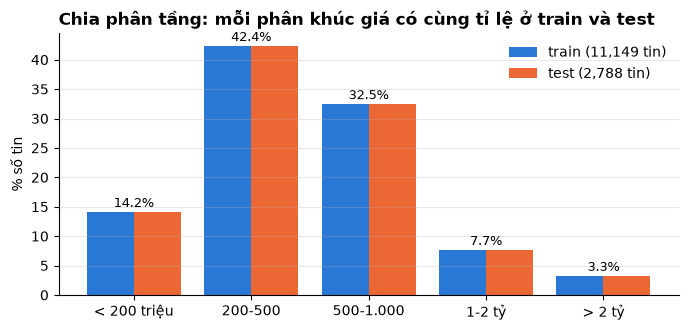

In [3]:
seg_share = pd.DataFrame({"train": pd.Series(seg_tr).value_counts(normalize=True),
                          "test": pd.Series(seg_te).value_counts(normalize=True)}).reindex(SEG_LABELS) * 100

fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(SEG_LABELS))
ax.bar(x - 0.2, seg_share["train"], 0.4, color=BLUE, label=f"train ({len(tr):,} tin)")
ax.bar(x + 0.2, seg_share["test"], 0.4, color=ORANGE, label=f"test ({len(te):,} tin)")
for i, v in enumerate(seg_share["train"]):
    ax.text(i, v + 0.8, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(SEG_LABELS)
ax.set_ylabel("% số tin"); ax.set_title("Chia phân tầng: mỗi phân khúc giá có cùng tỉ lệ ở train và test", loc="left")
ax.legend(frameon=False); ax.grid(axis="x", visible=False)
save(fig, "m01_chia_train_test"); plt.show()

## 2. Thước đo đánh giá

Dùng nhiều thước đo vì mỗi cái trả lời một câu hỏi khác nhau. Tất cả tính trên **giá thật (triệu đồng)**:

| Thước đo | Ý nghĩa | Vì sao dùng |
|---|---|---|
| **MAPE** | sai số phần trăm trung bình | **Thước đo chính.** Lệch 100 triệu là nhỏ với xe 3 tỷ nhưng rất lớn với xe 150 triệu |
| **MedAPE** | trung vị sai số phần trăm | Sai số "điển hình", không bị vài tin sai nặng kéo lệch |
| **MAE** | sai số tuyệt đối trung bình (triệu) | Dễ hiểu: "trung bình đoán lệch bao nhiêu tiền" |
| **RMSE** | căn trung bình bình phương sai số (triệu) | Phạt nặng các lỗi lớn (thường ở xe sang) |
| **R² (log)** | tỉ lệ biến thiên của log giá được giải thích | Đo trên đúng thang mô hình học; R² trên giá gốc bị vài xe đắt chi phối |
| **±10% / ±20%** | tỉ lệ tin được đoán lệch không quá 10% / 20% | Diễn giải cho người dùng: "bao nhiêu % xe được định giá sát" |

Ngoài ra luôn báo **MAPE theo từng phân khúc giá**: một con số trung bình sẽ che mất việc mô hình kém ở xe rất rẻ hoặc rất đắt.

**Mô hình mốc (baseline):** luôn đoán giá trung vị của tập train. Mô hình nào cũng phải tốt hơn hẳn mức này mới có ý nghĩa.

In [4]:
def regression_metrics(p_true, p_pred):
    p_pred = np.clip(p_pred, 1, None)
    err = p_pred - p_true
    ape = np.abs(err) / p_true
    lt, lp = np.log(p_true), np.log(p_pred)
    return {
        "MAPE": ape.mean(),
        "MedAPE": np.median(ape),
        "MAE (triệu)": np.mean(np.abs(err)),
        "RMSE (triệu)": np.sqrt(np.mean(err ** 2)),
        "R2 (log)": 1 - np.sum((lt - lp) ** 2) / np.sum((lt - lt.mean()) ** 2),
        "±10%": np.mean(ape <= 0.10),
        "±20%": np.mean(ape <= 0.20),
    }


def segment_mape(p_true, p_pred, seg):
    ape = np.abs(np.clip(p_pred, 1, None) - p_true) / p_true
    return {f"MAPE {s}": ape[seg == s].mean() for s in SEG_LABELS}


results, preds = {}, {}


def record(name, log_pred, fit_seconds):
    # Lưu metric trên tập test (log_pred là dự đoán trên thang log)
    p_pred = np.exp(log_pred)
    preds[name] = p_pred
    results[name] = {**regression_metrics(p_te, p_pred), **segment_mape(p_te, p_pred, seg_te),
                     "Thời gian fit (s)": fit_seconds}
    return pd.Series(results[name]).round(3).to_frame(name).T


t0 = time.time()
dummy = DummyRegressor(strategy="median").fit(XL_tr, y_tr)
record("Baseline (trung vị)", dummy.predict(XL_te), time.time() - t0)

,MAPE,MedAPE,MAE (triệu),RMSE (triệu),R2 (log),±10%,±20%,MAPE < 200 triệu,MAPE 200-500,MAPE 500-1.000,MAPE 1-2 tỷ,MAPE > 2 tỷ,Thời gian fit (s)
Baseline (trung vị),0.835,0.4,336.968,723.755,-0.003,0.137,0.256,3.498,0.385,0.307,0.641,0.854,0.001


## 3. Mô hình 1: Ridge Regression

### 3.1 Ý tưởng
Dự đoán log giá bằng tổ hợp tuyến tính của các đặc trưng:

$$\hat y = w_0 + w_1 x_1 + \dots + w_p x_p$$

Tìm trọng số $w$ bằng cách tối thiểu hóa sai số bình phương **cộng một khoản phạt** cho trọng số lớn (điều chuẩn L2):

$$J(w) = \underbrace{\frac{1}{2n}\sum_{i=1}^{n} (y_i - \hat y_i)^2}_{\text{sai số}} + \underbrace{\frac{\alpha}{2}\sum_{j=1}^{p} w_j^2}_{\text{phạt}} \qquad (w_0 \text{ không bị phạt})$$

**Vì sao cần khoản phạt:** sau one-hot có khoảng 260 cột, nhiều cột tương quan mạnh (hãng `Toyota` và dòng `Toyota Vios` luôn đi cùng nhau). Không có phạt (hồi quy tuyến tính thường), các hệ số có thể phình to và triệt tiêu lẫn nhau, mô hình nhạy với nhiễu. Khoản phạt kéo các hệ số về gần 0, mô hình ổn định hơn.

**Siêu tham số `alpha`:** quá nhỏ thì gần như không phạt (dễ overfit); quá lớn thì hệ số bị ép về 0 (underfit). Chọn bằng 5-fold cross-validation.

**Diễn giải hệ số:** vì mô hình dự đoán **log** giá, tăng $x_j$ thêm 1 đơn vị thì giá nhân với $e^{w_j}$, tức thay đổi khoảng $(e^{w_j}-1) \times 100\%$.

### 3.2 Bản thư viện (`sklearn.linear_model.Ridge`)

alpha tốt nhất: 0.5623 | CV RMSE (log) = 0.2879 | 8.9s


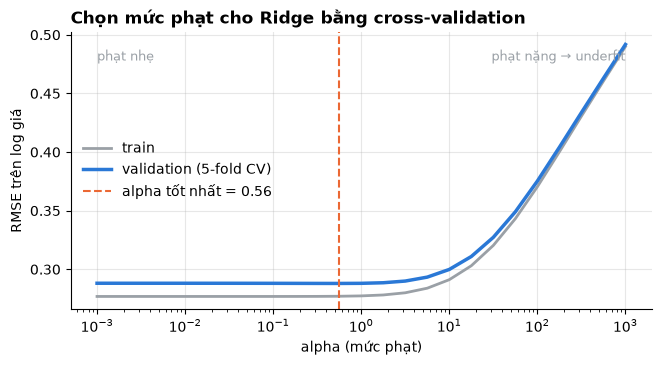

In [5]:
alphas = np.logspace(-3, 3, 25)
t0 = time.time()
gs_ridge = GridSearchCV(Ridge(), {"alpha": alphas}, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                        scoring="neg_root_mean_squared_error", n_jobs=-1, return_train_score=True)
gs_ridge.fit(XL_tr, y_tr)
best_alpha_lib = gs_ridge.best_params_["alpha"]
print(f"alpha tốt nhất: {best_alpha_lib:.4g} | CV RMSE (log) = {-gs_ridge.best_score_:.4f} | {time.time() - t0:.1f}s")

cvr = pd.DataFrame(gs_ridge.cv_results_)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(alphas, -cvr["mean_train_score"], color=GRAY, lw=2, label="train")
ax.plot(alphas, -cvr["mean_test_score"], color=BLUE, lw=2.5, label="validation (5-fold CV)")
ax.axvline(best_alpha_lib, color=ORANGE, ls="--", label=f"alpha tốt nhất = {best_alpha_lib:.2g}")
ax.set_xscale("log"); ax.set_xlabel("alpha (mức phạt)"); ax.set_ylabel("RMSE trên log giá")
ax.set_title("Chọn mức phạt cho Ridge bằng cross-validation", loc="left")
ax.text(1e-3, ax.get_ylim()[1] * 0.97, "phạt nhẹ", fontsize=9, color=GRAY, va="top")
ax.text(1e3, ax.get_ylim()[1] * 0.97, "phạt nặng → underfit", fontsize=9, color=GRAY, ha="right", va="top")
ax.legend(frameon=False, loc="center left")
save(fig, "m02_ridge_chon_alpha"); plt.show()

In [6]:
t0 = time.time()
ridge_lib = Ridge(alpha=best_alpha_lib).fit(XL_tr, y_tr)
record("Ridge - thư viện", ridge_lib.predict(XL_te), time.time() - t0)

,MAPE,MedAPE,MAE (triệu),RMSE (triệu),R2 (log),±10%,±20%,MAPE < 200 triệu,MAPE 200-500,MAPE 500-1.000,MAPE 1-2 tỷ,MAPE > 2 tỷ,Thời gian fit (s)
Ridge - thư viện,0.185,0.107,119.564,411.409,0.873,0.475,0.75,0.43,0.139,0.126,0.167,0.343,0.037


### 3.3 Bản tự cài đặt bằng NumPy

Hai cách tìm $w$, đều tự viết:

**1. Nghiệm đóng (normal equation).** Đạo hàm $J(w)$ theo $w$ rồi cho bằng 0, ta được hệ phương trình tuyến tính:

$$\left(\tfrac{1}{n}A^\top A + \alpha I'\right) w = \tfrac{1}{n}A^\top y$$

với $A$ là ma trận đặc trưng thêm cột 1 (cho $w_0$), $I'$ là ma trận đơn vị nhưng phần tử ứng với $w_0$ bằng 0 (không phạt hệ số tự do). Giải trực tiếp một lần, cho nghiệm chính xác.

**2. Gradient Descent có momentum Nesterov.** Bắt đầu từ $w = 0$, lặp lại: tính gradient $\nabla J = \frac{1}{n}A^\top(Aw - y) + \alpha I' w$ rồi bước ngược hướng gradient. Momentum Nesterov "nhìn trước" theo quán tính của bước cũ nên hội tụ nhanh hơn nhiều so với gradient descent thường. Bước học $\eta = 1/L$ với $L$ là trị riêng lớn nhất của ma trận Hessian, đảm bảo hội tụ. Cách này dùng để **minh họa quá trình tối ưu** và kiểm chứng chéo với nghiệm đóng.

**Chọn `alpha`** bằng **K-fold cross-validation tự viết** (xáo trộn chỉ số rồi chia thành K phần).

> Lưu ý quy đổi: `sklearn` tối thiểu hóa $\lVert y - Aw\rVert^2 + \alpha\lVert w\rVert^2$ (không chia $n$), còn bản tự viết chia $n$. Hai mô hình là một khi $\alpha_{\text{tự viết}} = \alpha_{\text{sklearn}} / n$. Notebook dùng cùng lưới alpha theo thang sklearn rồi quy đổi.

In [7]:
class RidgeScratch:
    # Ridge regression tự cài đặt: nghiệm đóng hoặc gradient descent (Nesterov). Hệ số tự do không bị phạt.

    def __init__(self, alpha=1.0, solver="closed", lr=None, n_iter=3000, tol=1e-9):
        self.alpha, self.solver, self.lr, self.n_iter, self.tol = alpha, solver, lr, n_iter, tol

    @staticmethod
    def _add_bias(X):
        return np.hstack([np.ones((X.shape[0], 1)), X])

    def fit(self, X, y):
        A = self._add_bias(X)
        n, p = A.shape
        reg = np.eye(p)
        reg[0, 0] = 0.0                                          # không phạt hệ số tự do w0
        if self.solver == "closed":
            # Giải hệ (AᵀA/n + αI') w = Aᵀy/n; dùng solve thay vì nghịch đảo để ổn định số
            self.w_ = np.linalg.solve(A.T @ A / n + self.alpha * reg, A.T @ y / n)
        else:
            H = A.T @ A / n + self.alpha * reg                   # Hessian của J (hằng số với bài toán bậc 2)
            lr = self.lr or 1.0 / np.linalg.eigvalsh(H).max()    # bước học 1/L đảm bảo hội tụ
            w = np.zeros(p)
            v = w.copy()                                         # điểm "nhìn trước" của Nesterov
            self.loss_ = []
            for t in range(1, self.n_iter + 1):
                grad = A.T @ (A @ v - y) / n + self.alpha * (reg @ v)
                w_new = v - lr * grad
                v = w_new + (t - 1) / (t + 2) * (w_new - w)      # bước quán tính
                w = w_new
                self.loss_.append(0.5 * np.mean((A @ w - y) ** 2) + 0.5 * self.alpha * np.sum(w[1:] ** 2))
                if np.linalg.norm(grad) < self.tol:
                    break
            self.w_ = w
        self.intercept_, self.coef_ = self.w_[0], self.w_[1:]
        return self

    def predict(self, X):
        return self._add_bias(X) @ self.w_


def kfold_indices(n, k, seed):
    # K-fold tự viết: xáo trộn chỉ số rồi cắt thành k phần, lần lượt lấy 1 phần làm validation
    idx = np.random.RandomState(seed).permutation(n)
    parts = np.array_split(idx, k)
    for i in range(k):
        yield np.concatenate(parts[:i] + parts[i + 1:]), parts[i]


def cv_rmse_ridge(X, y, alpha, k=5, seed=RANDOM_STATE):
    errs = []
    for tr_i, va_i in kfold_indices(len(y), k, seed):
        m = RidgeScratch(alpha).fit(X[tr_i], y[tr_i])
        errs.append(np.sqrt(np.mean((m.predict(X[va_i]) - y[va_i]) ** 2)))
    return np.mean(errs)


n_tr = len(y_tr)
t0 = time.time()
cv_scores = np.array([cv_rmse_ridge(XL_tr, y_tr, a / n_tr) for a in alphas])
best_alpha_scratch = alphas[cv_scores.argmin()]                  # theo thang sklearn để dễ so sánh
print(f"alpha tốt nhất (tự cài đặt): {best_alpha_scratch:.4g} (sklearn chọn {best_alpha_lib:.4g}) | "
      f"CV RMSE (log) = {cv_scores.min():.4f} | {time.time() - t0:.1f}s")

alpha tốt nhất (tự cài đặt): 0.5623 (sklearn chọn 0.5623) | CV RMSE (log) = 0.2879 | 3.5s


Nghiệm đóng so với sklearn (cùng alpha): lệch hệ số lớn nhất = 2.8e-11
Gradient descent (5000 vòng, 17.1s): J - J* = 3.6e-07; lệch dự đoán log giá lớn nhất trên test = 2.1e-03


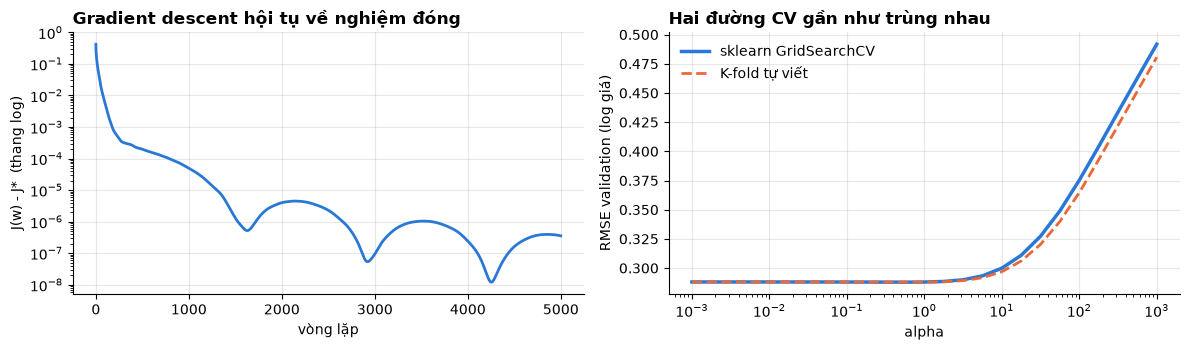

,MAPE,MedAPE,R2 (log),Thời gian fit (s)
Ridge - thư viện,0.1847,0.1066,0.8728,0.0366
Ridge - tự cài đặt (nghiệm đóng),0.1847,0.1066,0.8728,0.0185
Ridge - tự cài đặt (GD),0.1847,0.1067,0.8728,17.0611


In [8]:
a = best_alpha_scratch / n_tr
t0 = time.time(); ridge_closed = RidgeScratch(a, solver="closed").fit(XL_tr, y_tr); t_closed = time.time() - t0
t0 = time.time(); ridge_gd = RidgeScratch(a, solver="gd", n_iter=5000).fit(XL_tr, y_tr); t_gd = time.time() - t0

# Kiểm chứng 1: nghiệm đóng phải trùng sklearn khi cùng alpha
ridge_lib_same = Ridge(alpha=best_alpha_scratch).fit(XL_tr, y_tr)
d_coef = np.abs(ridge_closed.coef_ - ridge_lib_same.coef_).max()

# Kiểm chứng 2: gradient descent phải đưa J(w) về sát giá trị nhỏ nhất J* (đạt tại nghiệm đóng)
def J(model, X, y, alpha):
    return 0.5 * np.mean((model.predict(X) - y) ** 2) + 0.5 * alpha * np.sum(model.coef_ ** 2)

J_star = J(ridge_closed, XL_tr, y_tr, a)
gap = J(ridge_gd, XL_tr, y_tr, a) - J_star
d_pred = np.abs(ridge_gd.predict(XL_te) - ridge_closed.predict(XL_te)).max()

print(f"Nghiệm đóng so với sklearn (cùng alpha): lệch hệ số lớn nhất = {d_coef:.1e}")
print(f"Gradient descent ({len(ridge_gd.loss_)} vòng, {t_gd:.1f}s): J - J* = {gap:.1e}; "
      f"lệch dự đoán log giá lớn nhất trên test = {d_pred:.1e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(np.array(ridge_gd.loss_) - J_star, color=BLUE, lw=2)
axes[0].set_yscale("log"); axes[0].set_xlabel("vòng lặp"); axes[0].set_ylabel("J(w) - J*  (thang log)")
axes[0].set_title("Gradient descent hội tụ về nghiệm đóng", loc="left")
axes[1].plot(alphas, -cvr["mean_test_score"], color=BLUE, lw=2.5, label="sklearn GridSearchCV")
axes[1].plot(alphas, cv_scores, color=ORANGE, lw=2, ls="--", label="K-fold tự viết")
axes[1].set_xscale("log"); axes[1].set_xlabel("alpha"); axes[1].set_ylabel("RMSE validation (log giá)")
axes[1].set_title("Hai đường CV gần như trùng nhau", loc="left"); axes[1].legend(frameon=False)
fig.tight_layout(); save(fig, "m03_ridge_kiem_chung"); plt.show()

record("Ridge - tự cài đặt (nghiệm đóng)", ridge_closed.predict(XL_te), t_closed)
record("Ridge - tự cài đặt (GD)", ridge_gd.predict(XL_te), t_gd)
pd.DataFrame(results).T.loc[["Ridge - thư viện", "Ridge - tự cài đặt (nghiệm đóng)", "Ridge - tự cài đặt (GD)"],
                            ["MAPE", "MedAPE", "R2 (log)", "Thời gian fit (s)"]].round(4)

**Kết luận kiểm chứng Ridge:** với cùng `alpha`, hệ số của nghiệm đóng tự viết trùng `sklearn` đến sai số làm tròn của máy tính. Gradient descent đưa hàm mất mát về sát giá trị nhỏ nhất và cho dự đoán gần như trùng. Vậy bản tự cài đặt **đúng**.

Nếu `alpha` hai bên chọn hơi khác nhau, nguyên nhân là hai cách chia fold khác nhau trong khi đường CV rất phẳng quanh điểm tốt nhất (sai số validation gần như không đổi trong một khoảng rộng của `alpha`), nên kết quả trên test gần như như nhau.

### 3.4 Ridge học được gì?
Mỗi hệ số của cột one-hot cho biết thuộc tính đó làm giá **cao hơn hay thấp hơn bao nhiêu %** so với mức chung, khi giữ nguyên các đặc trưng khác.

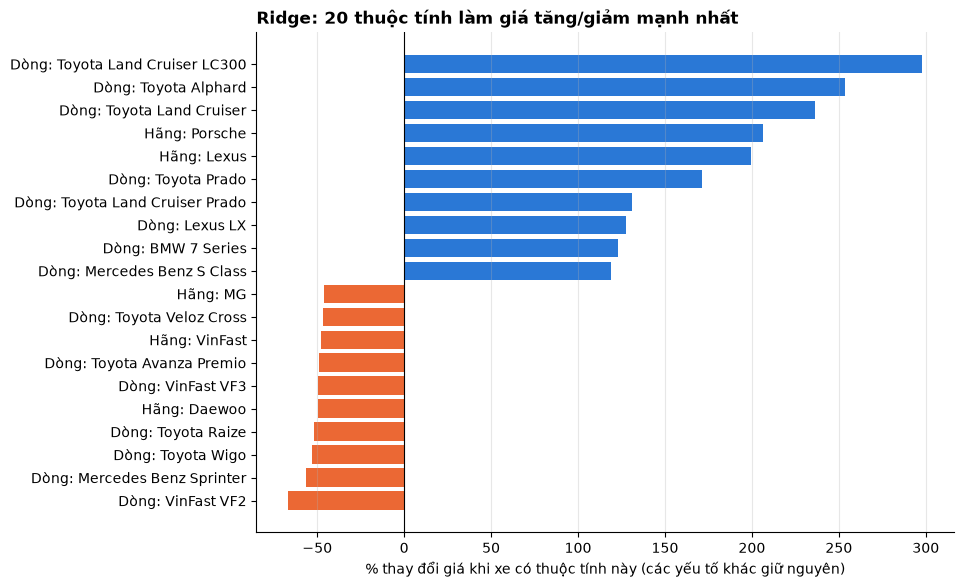

,hệ số (đã chuẩn hóa)
age,-0.986782
age_sq,0.295056
log_km,0.704689
carseats,0.031371
log_km_per_year,-0.620799
mileage_missing,-0.008271


In [9]:
coef = pd.Series(ridge_closed.coef_, index=names_lin)
effect = (np.exp(coef) - 1) * 100                                   # % thay đổi giá
onehot = effect[[n for n in names_lin if n.split("_")[0] in {"carbrand", "carmodel", "carorigin", "condition",
                                                             "gearbox", "fuel", "cartype"}]]
top = pd.concat([onehot.nsmallest(10), onehot.nlargest(10)]).sort_values()

fig, ax = plt.subplots(figsize=(9, 6.5))
labels = [n.replace("carmodel_grp_", "Dòng: ").replace("carbrand_grp_", "Hãng: ").replace("cartype_", "Kiểu dáng: ")
          .replace("fuel_", "Nhiên liệu: ").replace("gearbox_", "Hộp số: ").replace("carorigin_", "Xuất xứ: ")
          .replace("condition_ad_", "Tình trạng: ") for n in top.index]
ax.barh(labels, top.values, color=[ORANGE if v < 0 else BLUE for v in top.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("% thay đổi giá khi xe có thuộc tính này (các yếu tố khác giữ nguyên)")
ax.set_title("Ridge: 20 thuộc tính làm giá tăng/giảm mạnh nhất", loc="left")
ax.grid(axis="y", visible=False)
save(fig, "m04_ridge_he_so"); plt.show()

num_effect = pd.DataFrame({"hệ số (đã chuẩn hóa)": coef[NUM_LIN]})
num_effect

**Cách đọc đúng:** mô hình có **cả** cột hãng **và** cột dòng xe, nên hệ số của một dòng xe là phần **chênh thêm so với mức chung của hãng đó**. Ví dụ `Toyota Veloz Cross` mang dấu âm không có nghĩa xe này rẻ hơn mọi xe khác, mà là rẻ hơn mức trung bình của các xe Toyota cùng tuổi, cùng số km. Tương tự, `Hãng: VinFast` âm nghĩa là xe VinFast có giá thấp hơn mức chung của các xe cùng tuổi, cùng số km (nhiều khả năng do xe điện mất giá nhanh trên thị trường xe cũ).

Hệ số của các **đặc trưng số** khó đọc trực tiếp vì `age` và `age²` (hay `km` và `km/năm`) cùng mô tả một hiện tượng. Cách đọc đúng là xem **đường khấu hao** mà mô hình dự đoán khi tuổi xe tăng (mục 6.2).

## 4. Mô hình 2: Random Forest

### 4.1 Ý tưởng

**Thành phần: cây hồi quy (CART).** Cây chia dữ liệu bằng các câu hỏi có/không, ví dụ *"tuổi xe ≤ 5?"*, *"dòng xe là Toyota Vios?"*. Tại mỗi nút, thuật toán thử mọi đặc trưng và mọi ngưỡng, chọn phép chia làm **giảm tổng bình phương sai số (SSE)** nhiều nhất. Với nút có $n$ mẫu, tổng nhãn $S$, chia thành trái ($n_L$, $S_L$) và phải ($n_R$, $S_R$):

$$\text{gain} = \frac{S_L^2}{n_L} + \frac{S_R^2}{n_R} - \frac{S^2}{n}$$

Lặp lại cho đến khi đạt độ sâu tối đa hoặc nút quá ít mẫu. Giá trị dự đoán ở mỗi lá là **trung bình log giá** của các xe trong lá.

**Vấn đề của một cây:** cây sâu học thuộc dữ liệu train (độ chệch thấp) nhưng **phương sai cao**: đổi vài mẫu là cấu trúc cây thay đổi hẳn.

**Random Forest giải quyết bằng cách lấy trung bình nhiều cây khác nhau:**
1. **Bootstrap:** mỗi cây học trên một mẫu lấy ngẫu nhiên **có hoàn lại** từ train (cùng kích thước, khoảng 63% mẫu khác nhau).
2. **Chọn ngẫu nhiên đặc trưng:** mỗi lần chia nút chỉ xét một tỉ lệ `max_features` đặc trưng ngẫu nhiên, để các cây ít giống nhau.
3. **Lấy trung bình** dự đoán của tất cả các cây.

Trung bình của nhiều cây ít tương quan có phương sai nhỏ hơn hẳn một cây, trong khi độ chệch gần như không đổi.

**Out-of-bag (OOB):** khoảng 37% mẫu không được chọn vào bootstrap của mỗi cây. Dự đoán các mẫu này bằng những cây "chưa thấy" chúng cho ra một **ước lượng sai số khách quan mà không cần tập validation riêng**.

| Siêu tham số | Tác dụng |
|---|---|
| `n_estimators` | số cây; nhiều hơn thì ổn định hơn, đến một mức thì bão hòa |
| `max_depth` | độ sâu tối đa của cây |
| `min_samples_leaf` | số mẫu tối thiểu ở mỗi lá; lớn hơn thì cây "mượt" hơn |
| `max_features` | tỉ lệ đặc trưng xét ở mỗi lần chia; nhỏ hơn thì các cây đa dạng hơn |

### 4.2 Bản thư viện (`sklearn.ensemble.RandomForestRegressor`)
Tinh chỉnh bằng **Randomized Search + 3-fold CV** trên train: thử ngẫu nhiên một số cấu hình thay vì toàn bộ lưới, rẻ hơn mà thường tìm được cấu hình gần tốt nhất.

In [10]:
param_dist = {
    "n_estimators": [300],
    "max_depth": [20, 30, None],
    "min_samples_leaf": [1, 2, 3, 5],
    "max_features": [0.33, 0.5, 0.8],
}
t0 = time.time()
rs_rf = RandomizedSearchCV(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1), param_dist, n_iter=12,
                           cv=KFold(3, shuffle=True, random_state=RANDOM_STATE),
                           scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=1)
rs_rf.fit(XT_tr, y_tr)
print(f"Tìm kiếm mất {time.time() - t0:.0f}s | tốt nhất: {rs_rf.best_params_} | CV RMSE (log) = {-rs_rf.best_score_:.4f}")

cv_rf = pd.DataFrame(rs_rf.cv_results_)
cv_rf = cv_rf[[c for c in cv_rf if c.startswith("param_")] + ["mean_test_score"]]
cv_rf.columns = [c.replace("param_", "") for c in cv_rf.columns[:-1]] + ["CV RMSE (log)"]
cv_rf["CV RMSE (log)"] *= -1
cv_rf.sort_values("CV RMSE (log)").head(6).round(4)

Tìm kiếm mất 156s | tốt nhất: {'n_estimators': 300, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 30} | CV RMSE (log) = 0.2741


,n_estimators,min_samples_leaf,max_features,max_depth,CV RMSE (log)
4,300,1,0.50,30,0.2741
7,300,1,0.33,30,0.2747
9,300,2,0.50,30,0.2819
6,300,2,0.80,30,0.2827
1,300,2,0.33,30,0.2839
11,300,3,0.80,None,0.2864


In [11]:
t0 = time.time()
rf_lib = RandomForestRegressor(**rs_rf.best_params_, random_state=RANDOM_STATE, n_jobs=-1, oob_score=True).fit(XT_tr, y_tr)
t_rf_lib = time.time() - t0
print(f"OOB R² (log) = {rf_lib.oob_score_:.4f} | huấn luyện {t_rf_lib:.1f}s")
record("Random Forest - thư viện", rf_lib.predict(XT_te), t_rf_lib)

OOB R² (log) = 0.8956 | huấn luyện 7.9s


,MAPE,MedAPE,MAE (triệu),RMSE (triệu),R2 (log),±10%,±20%,MAPE < 200 triệu,MAPE 200-500,MAPE 500-1.000,MAPE 1-2 tỷ,MAPE > 2 tỷ,Thời gian fit (s)
Random Forest - thư viện,0.155,0.09,102.137,372.406,0.891,0.539,0.801,0.347,0.117,0.109,0.157,0.27,7.949


### 4.3 Bản tự cài đặt bằng NumPy

Gồm ba lớp:

| Lớp | Nhiệm vụ |
|---|---|
| `Binner` | rời rạc hóa mỗi đặc trưng thành tối đa 32 "bin" theo phân vị (fit trên train) |
| `RegressionTreeScratch` | cây hồi quy CART: tìm phép chia tốt nhất theo công thức gain ở trên |
| `RandomForestScratch` | bootstrap + chọn ngẫu nhiên đặc trưng + lấy trung bình; tính OOB và độ quan trọng đặc trưng |

**Tăng tốc bằng histogram.** Cách làm cơ bản phải sắp xếp từng cột ở mỗi nút để thử mọi ngưỡng, rất chậm khi viết bằng Python thuần. Thay vào đó, mỗi đặc trưng được chia sẵn thành tối đa 32 bin **một lần** (kỹ thuật của LightGBM / HistGradientBoosting). Tại mỗi nút chỉ cần đếm số mẫu và tổng nhãn trong từng bin (`np.bincount`), rồi cộng dồn (`np.cumsum`) là có gain của **mọi ngưỡng cùng lúc**. Cột one-hot chỉ có 2 giá trị nên không mất thông tin; cột số mất rất ít độ chi tiết.

**Độ quan trọng đặc trưng** = tổng gain mà đặc trưng đó mang lại ở mọi nút của mọi cây, chuẩn hóa về tổng bằng 1 (cùng định nghĩa với `sklearn`).

In [12]:
class Binner:
    # Rời rạc hóa mỗi cột thành tối đa n_bins bin theo phân vị (fit trên train)

    def __init__(self, n_bins=32):
        self.n_bins = n_bins

    def fit(self, X):
        qs = np.linspace(0, 1, self.n_bins + 1)[1:-1]
        self.edges_ = [np.unique(np.quantile(X[:, j], qs)) for j in range(X.shape[1])]
        return self

    def transform(self, X):
        out = np.empty(X.shape, dtype=np.uint8)
        for j, e in enumerate(self.edges_):
            out[:, j] = np.searchsorted(e, X[:, j], side="left")
        return out


class RegressionTreeScratch:
    # Cây hồi quy CART: chia nút theo mức giảm SSE lớn nhất, tìm ngưỡng bằng histogram

    def __init__(self, max_depth=12, min_samples_leaf=5, max_features=0.5, n_bins=32, random_state=0):
        self.max_depth, self.min_samples_leaf = max_depth, min_samples_leaf
        self.max_features, self.n_bins = max_features, n_bins
        self.rng = np.random.RandomState(random_state)

    def _best_split(self, Xb, y, idx, feats):
        n = len(idx)
        sub = Xb[np.ix_(idx, feats)].astype(np.int64)                     # (n mẫu, k đặc trưng)
        flat = (sub + np.arange(len(feats)) * self.n_bins).ravel()        # mã (đặc trưng, bin) duy nhất
        size = len(feats) * self.n_bins
        cnt = np.bincount(flat, minlength=size).reshape(len(feats), self.n_bins)                 # số mẫu mỗi bin
        sm = np.bincount(flat, weights=np.repeat(y[idx], len(feats)), minlength=size).reshape(len(feats), self.n_bins)
        cl, sl = np.cumsum(cnt, axis=1), np.cumsum(sm, axis=1)            # nhánh trái: bin <= b
        total = y[idx].sum()
        cr, sr = n - cl, total - sl                                       # nhánh phải
        valid = (cl >= self.min_samples_leaf) & (cr >= self.min_samples_leaf)
        with np.errstate(divide="ignore", invalid="ignore"):
            gain = sl ** 2 / cl + sr ** 2 / cr - total ** 2 / n           # mức giảm SSE
        gain[~valid] = -np.inf
        j, b = np.unravel_index(np.argmax(gain), gain.shape)
        if np.isfinite(gain[j, b]) and gain[j, b] > 1e-12:
            return feats[j], b, gain[j, b]
        return None, None, 0.0

    def fit(self, Xb, y, idx=None):
        n_feat = Xb.shape[1]
        k = max(1, int(round(self.max_features * n_feat)))
        self.feature_, self.thr_, self.left_, self.right_, self.value_ = [], [], [], [], []
        self.importance_ = np.zeros(n_feat)
        idx = np.arange(len(y)) if idx is None else idx

        def new_node(i):
            self.feature_.append(-1); self.thr_.append(-1)
            self.left_.append(-1); self.right_.append(-1)
            self.value_.append(y[i].mean())                               # dự đoán ở lá = trung bình nhãn
            return len(self.value_) - 1

        stack = [(new_node(idx), idx, 0)]                                 # dựng cây bằng ngăn xếp (không đệ quy)
        while stack:
            node, i, depth = stack.pop()
            if depth >= self.max_depth or len(i) < 2 * self.min_samples_leaf or np.ptp(y[i]) == 0:
                continue
            feats = self.rng.choice(n_feat, k, replace=False)            # chọn ngẫu nhiên đặc trưng
            f, b, gain = self._best_split(Xb, y, i, feats)
            if f is None:
                continue
            go_left = Xb[i, f] <= b
            self.feature_[node], self.thr_[node] = f, b
            self.importance_[f] += gain
            li, ri = new_node(i[go_left]), new_node(i[~go_left])
            self.left_[node], self.right_[node] = li, ri
            stack.append((li, i[go_left], depth + 1))
            stack.append((ri, i[~go_left], depth + 1))
        self.feature_, self.thr_ = np.array(self.feature_), np.array(self.thr_)
        self.left_, self.right_, self.value_ = np.array(self.left_), np.array(self.right_), np.array(self.value_)
        return self

    def predict(self, Xb):
        node = np.zeros(len(Xb), dtype=np.int64)                          # mọi mẫu bắt đầu ở gốc
        while True:
            f = self.feature_[node]
            active = f >= 0                                               # mẫu chưa tới lá
            if not active.any():
                return self.value_[node]
            rows = np.where(active)[0]
            go_left = Xb[rows, f[rows]] <= self.thr_[node[rows]]
            node[rows] = np.where(go_left, self.left_[node[rows]], self.right_[node[rows]])


class RandomForestScratch:
    # Random Forest: bootstrap + chọn ngẫu nhiên đặc trưng + lấy trung bình; có OOB và độ quan trọng đặc trưng

    def __init__(self, n_estimators=100, max_depth=12, min_samples_leaf=5, max_features=0.5, n_bins=32, random_state=0):
        self.n_estimators, self.max_depth = n_estimators, max_depth
        self.min_samples_leaf, self.max_features = min_samples_leaf, max_features
        self.n_bins, self.random_state = n_bins, random_state

    def fit(self, X, y):
        self.binner_ = Binner(self.n_bins).fit(X)
        Xb = self.binner_.transform(X)
        n = len(y)
        rng = np.random.RandomState(self.random_state)
        self.trees_, self.oob_curve_ = [], []
        oob_sum, oob_cnt = np.zeros(n), np.zeros(n)
        for _ in range(self.n_estimators):
            boot = rng.randint(0, n, n)                                   # bootstrap: lấy n mẫu có hoàn lại
            tree = RegressionTreeScratch(self.max_depth, self.min_samples_leaf, self.max_features,
                                         self.n_bins, random_state=rng.randint(1 << 30)).fit(Xb, y, boot)
            self.trees_.append(tree)
            oob = np.setdiff1d(np.arange(n), boot)                        # mẫu cây này chưa thấy
            oob_sum[oob] += tree.predict(Xb[oob]); oob_cnt[oob] += 1
            seen = oob_cnt > 0
            self.oob_curve_.append(np.sqrt(np.mean((y[seen] - oob_sum[seen] / oob_cnt[seen]) ** 2)))
        seen = oob_cnt > 0
        oob_pred = oob_sum[seen] / oob_cnt[seen]
        self.oob_rmse_ = np.sqrt(np.mean((y[seen] - oob_pred) ** 2))
        self.oob_r2_ = 1 - np.sum((y[seen] - oob_pred) ** 2) / np.sum((y[seen] - y[seen].mean()) ** 2)
        imp = np.sum([t.importance_ for t in self.trees_], axis=0)
        self.feature_importances_ = imp / imp.sum()
        return self

    def predict(self, X):
        Xb = self.binner_.transform(X)
        return np.mean([t.predict(Xb) for t in self.trees_], axis=0)      # trung bình các cây

### 4.4 Kiểm chứng thành phần: một cây tự viết so với `DecisionTreeRegressor`

Trước khi dựng rừng, kiểm tra **một cây** tự viết (xét mọi đặc trưng ở mỗi nút, `max_features = 1`) với cây của `sklearn` khi dùng **cùng tham số**. Nếu hai cây cho chất lượng gần như nhau thì lớp cây đúng, và rừng tự viết chỉ cần thêm bootstrap và lấy trung bình.

In [13]:
from sklearn.metrics import r2_score

DT_CFG = {"max_depth": 10**6, "min_samples_leaf": 5}                       # cây sâu không giới hạn, lá ≥ 5 mẫu
binner_chk = Binner(32).fit(XT_tr)
Xb_tr, Xb_te = binner_chk.transform(XT_tr), binner_chk.transform(XT_te)

t0 = time.time(); tree_s = RegressionTreeScratch(**DT_CFG, max_features=1.0).fit(Xb_tr, y_tr); t_tree_s = time.time() - t0
t0 = time.time(); tree_l = DecisionTreeRegressor(min_samples_leaf=5, random_state=RANDOM_STATE).fit(XT_tr, y_tr); t_tree_l = time.time() - t0

tree_cmp = pd.DataFrame({
    "số nút": [tree_l.tree_.node_count, len(tree_s.value_)],
    "R² (log) train": [r2_score(y_tr, tree_l.predict(XT_tr)), r2_score(y_tr, tree_s.predict(Xb_tr))],
    "R² (log) test": [r2_score(y_te, tree_l.predict(XT_te)), r2_score(y_te, tree_s.predict(Xb_te))],
    "MAPE test": [regression_metrics(p_te, np.exp(tree_l.predict(XT_te)))["MAPE"],
                  regression_metrics(p_te, np.exp(tree_s.predict(Xb_te)))["MAPE"]],
    "thời gian (s)": [t_tree_l, t_tree_s],
}, index=["Một cây - thư viện", "Một cây - tự cài đặt"])
tree_cmp.round(4)

,số nút,R² (log) train,R² (log) test,MAPE test,thời gian (s)
Một cây - thư viện,3481,0.9292,0.8420,0.1964,0.2803
Một cây - tự cài đặt,3429,0.9265,0.8513,0.1856,1.6265


Hai cây có số nút và R² gần như nhau, nên **lớp cây tự viết đúng**. Chú ý khoảng cách lớn giữa R² train và R² test của một cây: đó chính là **phương sai cao** mà Random Forest khắc phục.

> Bảng trên dùng tập test chỉ để **kiểm tra tính đúng của code** (hai bản cài đặt có cho cùng kết quả không), không dùng để chọn tham số hay mô hình.

### 4.5 Tinh chỉnh bản tự viết bằng OOB
Bản tự viết chạy bằng Python thuần nên chậm hơn thư viện nhiều. Thay vì CV (huấn luyện 3-5 lần mỗi cấu hình), dùng **OOB RMSE**: mỗi cấu hình chỉ huấn luyện **một lần** với 30 cây. Không gian tham số cùng phạm vi với bản thư viện.

In [14]:
space = [{"max_depth": d, "min_samples_leaf": l, "max_features": f}
         for d in [20, 30] for l in [1, 2, 3] for f in [0.33, 0.5]]
pick = np.random.RandomState(RANDOM_STATE).choice(len(space), 6, replace=False)
trials = []
t0 = time.time()
for k, i in enumerate(pick):
    cfg = space[i]
    t1 = time.time()
    m = RandomForestScratch(n_estimators=30, random_state=RANDOM_STATE, **cfg).fit(XT_tr, y_tr)
    trials.append({**cfg, "OOB RMSE (log)": m.oob_rmse_, "OOB R²": m.oob_r2_, "giây": time.time() - t1})
    print(f"[{k + 1}/{len(pick)}] {cfg} -> OOB RMSE {m.oob_rmse_:.4f} ({time.time() - t1:.0f}s)")
trials = pd.DataFrame(trials).sort_values("OOB RMSE (log)").reset_index(drop=True)
best_cfg = {"max_depth": int(trials.loc[0, "max_depth"]), "min_samples_leaf": int(trials.loc[0, "min_samples_leaf"]),
            "max_features": float(trials.loc[0, "max_features"])}
print(f"\nTìm kiếm mất {time.time() - t0:.0f}s | cấu hình tốt nhất: {best_cfg}")
trials.round(4)

[1/6] {'max_depth': 30, 'min_samples_leaf': 3, 'max_features': 0.33} -> OOB RMSE 0.2779 (21s)


[2/6] {'max_depth': 30, 'min_samples_leaf': 2, 'max_features': 0.5} -> OOB RMSE 0.2704 (36s)


[3/6] {'max_depth': 20, 'min_samples_leaf': 1, 'max_features': 0.33} -> OOB RMSE 0.2938 (24s)


[4/6] {'max_depth': 30, 'min_samples_leaf': 2, 'max_features': 0.33} -> OOB RMSE 0.2741 (28s)


[5/6] {'max_depth': 20, 'min_samples_leaf': 3, 'max_features': 0.5} -> OOB RMSE 0.2972 (23s)


[6/6] {'max_depth': 20, 'min_samples_leaf': 2, 'max_features': 0.33} -> OOB RMSE 0.2946 (19s)

Tìm kiếm mất 151s | cấu hình tốt nhất: {'max_depth': 30, 'min_samples_leaf': 2, 'max_features': 0.5}


,max_depth,min_samples_leaf,max_features,OOB RMSE (log),OOB R²,giây
0,30,2,0.50,0.2704,0.8858,35.9110
1,30,2,0.33,0.2741,0.8826,27.7308
2,30,3,0.33,0.2779,0.8794,21.4461
3,20,1,0.33,0.2938,0.8651,23.6438
4,20,2,0.33,0.2946,0.8644,19.4886
5,20,3,0.50,0.2972,0.8620,22.8715


### 4.6 Huấn luyện rừng tự viết: từ một cây đến nhiều cây
Huấn luyện với cấu hình tốt nhất và theo dõi **OOB RMSE khi số cây tăng dần**. Biểu đồ cho thấy trực quan vì sao "rừng" tốt hơn "cây": sai số giảm rất nhanh trong vài chục cây đầu rồi **bão hòa**; thêm cây sau điểm đó chỉ tốn thời gian.

Huấn luyện 100 cây: 152s | OOB R² (log) = 0.8916 | OOB RMSE (log) = 0.2634
(Bản thư viện: OOB R² (log) = 0.8956)


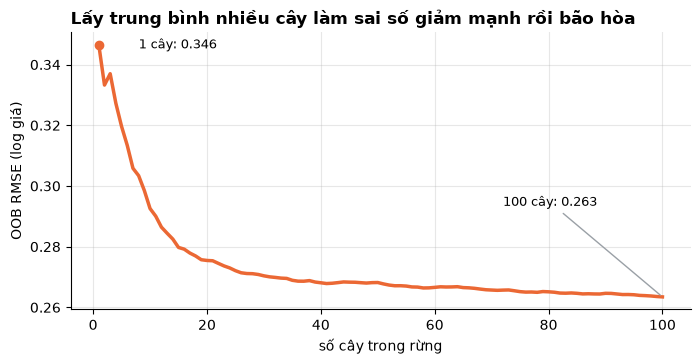

,MAPE,MedAPE,MAE (triệu),RMSE (triệu),R2 (log),±10%,±20%,MAPE < 200 triệu,MAPE 200-500,MAPE 500-1.000,MAPE 1-2 tỷ,MAPE > 2 tỷ,Thời gian fit (s)
Random Forest - tự cài đặt,0.157,0.09,106.029,388.394,0.887,0.546,0.796,0.356,0.116,0.108,0.158,0.304,151.72


In [15]:
N_TREES = 100
t0 = time.time()
rf_s = RandomForestScratch(n_estimators=N_TREES, random_state=RANDOM_STATE, **best_cfg).fit(XT_tr, y_tr)
t_rf_s = time.time() - t0
print(f"Huấn luyện {N_TREES} cây: {t_rf_s:.0f}s | OOB R² (log) = {rf_s.oob_r2_:.4f} | OOB RMSE (log) = {rf_s.oob_rmse_:.4f}")
print(f"(Bản thư viện: OOB R² (log) = {rf_lib.oob_score_:.4f})")

curve = np.array(rf_s.oob_curve_)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(np.arange(1, N_TREES + 1), curve, color=ORANGE, lw=2.5)
ax.scatter([1], [curve[0]], color=ORANGE, zorder=3)
ax.annotate(f"1 cây: {curve[0]:.3f}", (1, curve[0]), xytext=(8, curve[0]), fontsize=9, va="center")
ax.annotate(f"{N_TREES} cây: {curve[-1]:.3f}", (N_TREES, curve[-1]), xytext=(N_TREES * 0.72, curve[-1] + 0.03),
            fontsize=9, arrowprops=dict(arrowstyle="-", color=GRAY))
ax.set_xlabel("số cây trong rừng"); ax.set_ylabel("OOB RMSE (log giá)")
ax.set_title("Lấy trung bình nhiều cây làm sai số giảm mạnh rồi bão hòa", loc="left")
save(fig, "m05_rf_so_cay"); plt.show()

record("Random Forest - tự cài đặt", rf_s.predict(XT_te), t_rf_s)

## 5. Kết quả trên tập test

Đây là lần **duy nhất** tập test được dùng để đánh giá. Mọi mô hình học trên cùng tập train và được đánh giá trên cùng 2.788 tin test.

In [16]:
ORDER = ["Baseline (trung vị)", "Ridge - thư viện", "Ridge - tự cài đặt (nghiệm đóng)", "Ridge - tự cài đặt (GD)",
         "Random Forest - thư viện", "Random Forest - tự cài đặt"]
res = pd.DataFrame(results).T.loc[ORDER].astype(float)
main_cols = ["MAPE", "MedAPE", "MAE (triệu)", "RMSE (triệu)", "R2 (log)", "±10%", "±20%", "Thời gian fit (s)"]
seg_cols = [f"MAPE {s}" for s in SEG_LABELS]
res[main_cols].round(3)

,MAPE,MedAPE,MAE (triệu),RMSE (triệu),R2 (log),±10%,±20%,Thời gian fit (s)
Baseline (trung vị),0.835,0.400,336.968,723.755,-0.003,0.137,0.256,0.001
Ridge - thư viện,0.185,0.107,119.564,411.409,0.873,0.475,0.750,0.037
Ridge - tự cài đặt (nghiệm đóng),0.185,0.107,119.564,411.409,0.873,0.475,0.750,0.019
Ridge - tự cài đặt (GD),0.185,0.107,119.553,411.404,0.873,0.476,0.750,17.061
Random Forest - thư viện,0.155,0.090,102.137,372.406,0.891,0.539,0.801,7.949
Random Forest - tự cài đặt,0.157,0.090,106.029,388.394,0.887,0.546,0.796,151.720


In [17]:
res[seg_cols].round(3)

,MAPE < 200 triệu,MAPE 200-500,MAPE 500-1.000,MAPE 1-2 tỷ,MAPE > 2 tỷ
Baseline (trung vị),3.498,0.385,0.307,0.641,0.854
Ridge - thư viện,0.430,0.139,0.126,0.167,0.343
Ridge - tự cài đặt (nghiệm đóng),0.430,0.139,0.126,0.167,0.343
Ridge - tự cài đặt (GD),0.430,0.139,0.126,0.167,0.343
Random Forest - thư viện,0.347,0.117,0.109,0.157,0.270
Random Forest - tự cài đặt,0.356,0.116,0.108,0.158,0.304


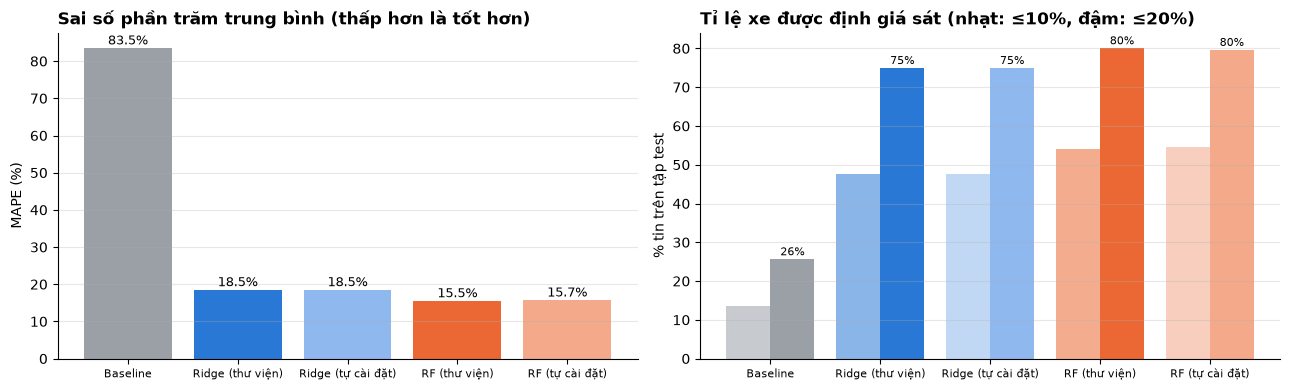

In [18]:
SHOW = ["Ridge - thư viện", "Ridge - tự cài đặt (nghiệm đóng)", "Random Forest - thư viện", "Random Forest - tự cài đặt"]
SHORT = {"Baseline (trung vị)": "Baseline", "Ridge - thư viện": "Ridge (thư viện)",
         "Ridge - tự cài đặt (nghiệm đóng)": "Ridge (tự cài đặt)", "Ridge - tự cài đặt (GD)": "Ridge (tự cài đặt, GD)",
         "Random Forest - thư viện": "RF (thư viện)", "Random Forest - tự cài đặt": "RF (tự cài đặt)"}
COL = {"Baseline (trung vị)": GRAY, "Ridge - thư viện": BLUE, "Ridge - tự cài đặt (nghiệm đóng)": LIGHT_BLUE,
       "Random Forest - thư viện": ORANGE, "Random Forest - tự cài đặt": LIGHT_ORANGE}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
names = ["Baseline (trung vị)"] + SHOW
vals = res.loc[names, "MAPE"] * 100
axes[0].bar([SHORT[n] for n in names], vals, color=[COL[n] for n in names])
for i, v in enumerate(vals):
    axes[0].text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
axes[0].set_ylabel("MAPE (%)"); axes[0].set_title("Sai số phần trăm trung bình (thấp hơn là tốt hơn)", loc="left")
axes[0].tick_params(axis="x", labelsize=8); axes[0].grid(axis="x", visible=False)

x = np.arange(len(names))
axes[1].bar(x - 0.2, res.loc[names, "±10%"] * 100, 0.4, color=[COL[n] for n in names], alpha=0.55, label="lệch ≤ 10%")
axes[1].bar(x + 0.2, res.loc[names, "±20%"] * 100, 0.4, color=[COL[n] for n in names], label="lệch ≤ 20%")
for i, n in enumerate(names):
    axes[1].text(i + 0.2, res.loc[n, "±20%"] * 100 + 1, f"{res.loc[n, '±20%'] * 100:.0f}%", ha="center", fontsize=8)
axes[1].set_xticks(x); axes[1].set_xticklabels([SHORT[n] for n in names], fontsize=8)
axes[1].set_ylabel("% tin trên tập test"); axes[1].set_title("Tỉ lệ xe được định giá sát (nhạt: ≤10%, đậm: ≤20%)", loc="left")
axes[1].grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "m06_so_sanh_tong"); plt.show()

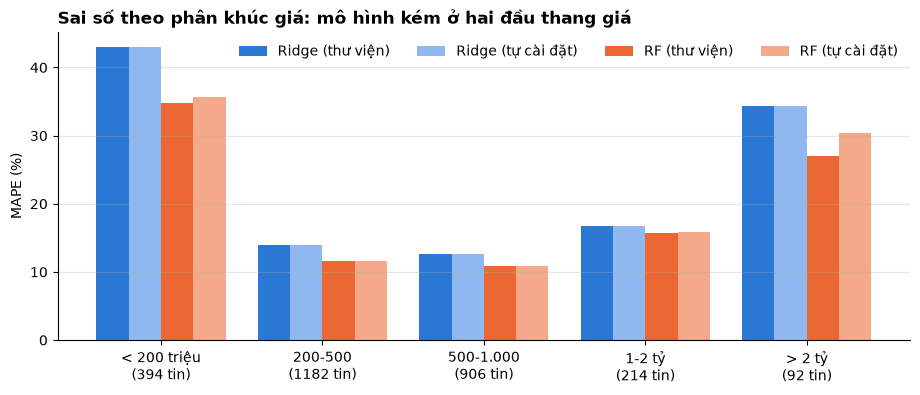

In [19]:
fig, ax = plt.subplots(figsize=(11, 4))
w = 0.8 / len(SHOW)
x = np.arange(len(SEG_LABELS))
for k, n in enumerate(SHOW):
    v = res.loc[n, seg_cols].values * 100
    ax.bar(x + (k - 1.5) * w, v, w, color=COL[n], label=SHORT[n])
seg_n = pd.Series(seg_te).value_counts().reindex(SEG_LABELS)
ax.set_xticks(x); ax.set_xticklabels([f"{s}\n({seg_n[s]} tin)" for s in SEG_LABELS])
ax.set_ylabel("MAPE (%)"); ax.set_title("Sai số theo phân khúc giá: mô hình kém ở hai đầu thang giá", loc="left")
ax.legend(frameon=False, ncol=4); ax.grid(axis="x", visible=False)
save(fig, "m07_mape_phan_khuc"); plt.show()

### 5.1 Dự đoán so với giá thật
Mỗi điểm là một xe trong tập test. Điểm càng sát đường chéo thì dự đoán càng đúng. Trục dùng thang log để thấy được cả xe 50 triệu và xe 10 tỷ; trên thang log, khoảng cách tới đường chéo chính là **sai số phần trăm**.

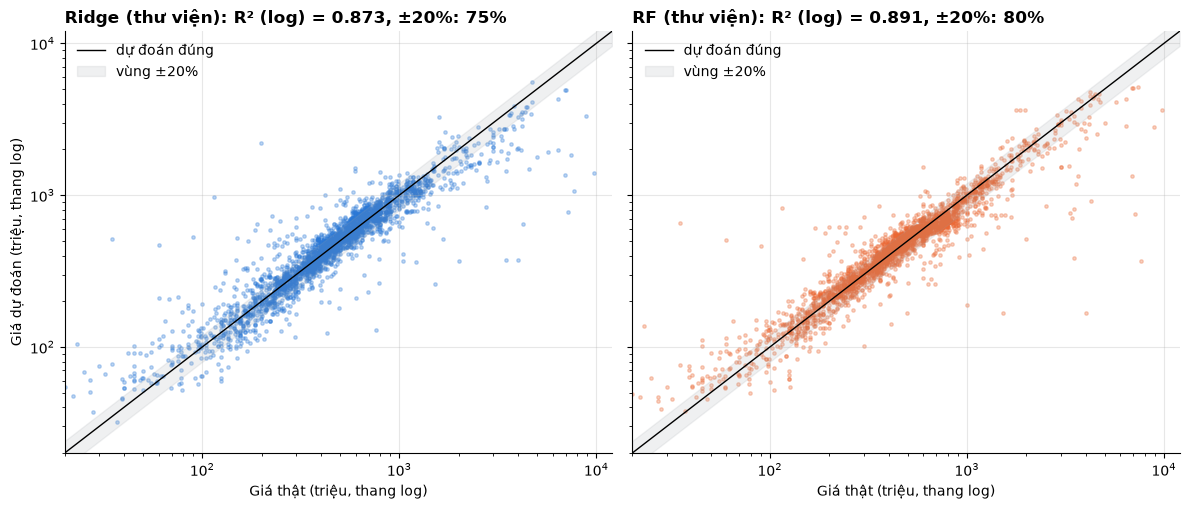

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
lim = [20, 12000]
for ax, n in zip(axes, ["Ridge - thư viện", "Random Forest - thư viện"]):
    ax.scatter(p_te, preds[n], s=6, alpha=0.3, color=COL[n])
    ax.plot(lim, lim, color="black", lw=1, label="dự đoán đúng")
    ax.fill_between(lim, [v * 0.8 for v in lim], [v * 1.2 for v in lim], color=GRAY, alpha=0.15, label="vùng ±20%")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("Giá thật (triệu, thang log)")
    ax.set_title(f"{SHORT[n]}: R² (log) = {res.loc[n, 'R2 (log)']:.3f}, ±20%: {res.loc[n, '±20%']:.0%}", loc="left")
    ax.legend(frameon=False, loc="upper left")
axes[0].set_ylabel("Giá dự đoán (triệu, thang log)")
fig.tight_layout(); save(fig, "m08_du_doan_vs_thuc_te"); plt.show()

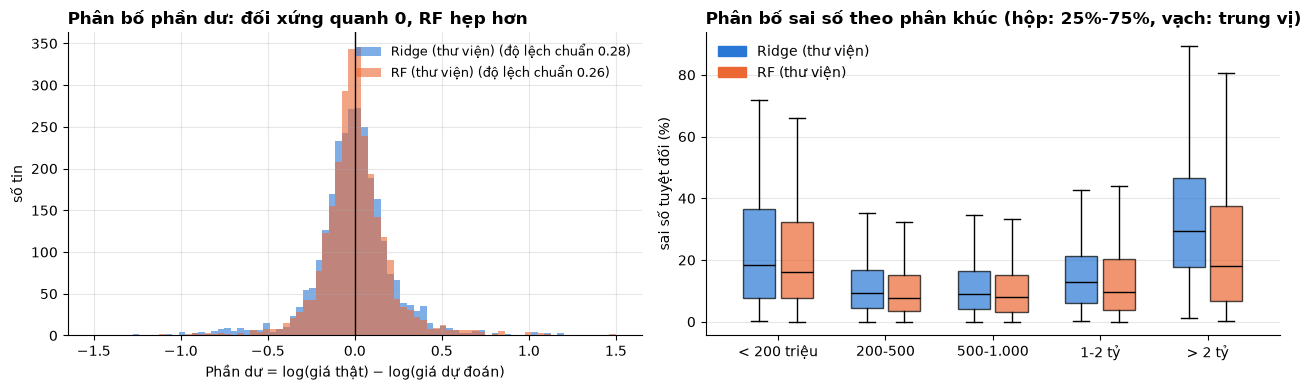

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for n in ["Ridge - thư viện", "Random Forest - thư viện"]:
    resid = np.log(p_te) - np.log(preds[n])
    axes[0].hist(resid, bins=80, range=(-1.5, 1.5), color=COL[n], alpha=0.6,
                 label=f"{SHORT[n]} (độ lệch chuẩn {resid.std():.2f})")
axes[0].axvline(0, color="black", lw=1)
axes[0].set_xlabel("Phần dư = log(giá thật) − log(giá dự đoán)")
axes[0].set_ylabel("số tin"); axes[0].set_title("Phân bố phần dư: đối xứng quanh 0, RF hẹp hơn", loc="left")
axes[0].legend(frameon=False, fontsize=9)

ape = {n: np.abs(preds[n] - p_te) / p_te * 100 for n in ["Ridge - thư viện", "Random Forest - thư viện"]}
pos = np.arange(len(SEG_LABELS))
for k, n in enumerate(ape):
    data = [ape[n][seg_te == s] for s in SEG_LABELS]
    bp = axes[1].boxplot(data, positions=pos + (k - 0.5) * 0.35, widths=0.3, showfliers=False, patch_artist=True,
                         medianprops=dict(color="black"))
    for b in bp["boxes"]:
        b.set_facecolor(COL[n]); b.set_alpha(0.7)
axes[1].set_xticks(pos); axes[1].set_xticklabels(SEG_LABELS)
axes[1].set_ylabel("sai số tuyệt đối (%)")
axes[1].set_title("Phân bố sai số theo phân khúc (hộp: 25%-75%, vạch: trung vị)", loc="left")
axes[1].legend([plt.Rectangle((0, 0), 1, 1, color=COL[n]) for n in ape], [SHORT[n] for n in ape], frameon=False)
axes[1].grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "m09_phan_du"); plt.show()

### 5.2 Chênh lệch giữa các mô hình có ý nghĩa không? (bootstrap)
Tập test hữu hạn nên MAPE chỉ là một ước lượng: đổi sang một tập test khác thì con số sẽ khác đi một chút. **Bootstrap** ước lượng mức dao động đó: lấy mẫu lại tập test có hoàn lại 1.000 lần, mỗi lần tính lại MAPE, rồi lấy khoảng chứa 95% giá trị ở giữa làm **khoảng tin cậy 95%**.

Để so sánh **hai** mô hình, không nên chỉ nhìn hai khoảng tin cậy có chồng nhau không (cách này quá khắt khe). Cách đúng là **bootstrap ghép cặp**: trong mỗi lần lấy mẫu, tính **hiệu MAPE của hai mô hình trên cùng các xe**. Nếu khoảng tin cậy 95% của hiệu không chứa 0 thì chênh lệch có ý nghĩa thống kê.

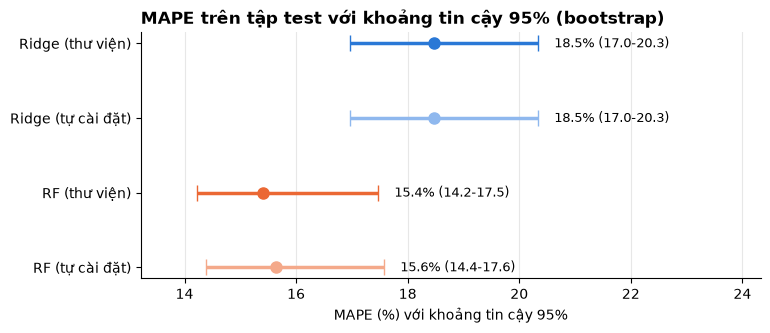

Hiệu MAPE (điểm %), bootstrap ghép cặp:


,2.5%,trung vị,97.5%,có ý nghĩa?
Ridge − Random Forest (thư viện),2.08,2.97,3.97,có
RF tự cài đặt − RF thư viện,-0.04,0.19,0.46,không (khoảng chứa 0)
Ridge tự cài đặt − Ridge thư viện,-0.00,-0.00,0.00,không (khoảng chứa 0)


In [22]:
N_BOOT = 1000
boot_idx = np.random.RandomState(RANDOM_STATE).randint(0, len(p_te), (N_BOOT, len(p_te)))   # cùng các mẫu cho mọi mô hình
ape_te = {n: np.abs(np.clip(preds[n], 1, None) - p_te) / p_te for n in SHOW}
boot = {n: ape_te[n][boot_idx].mean(axis=1) for n in SHOW}                                  # MAPE của từng lần lấy mẫu
ci = pd.DataFrame({n: np.percentile(b, [2.5, 50, 97.5]) for n, b in boot.items()}, index=["2.5%", "trung vị", "97.5%"]).T

# Bootstrap ghép cặp: hiệu MAPE trên cùng các xe
pairs = {"Ridge − Random Forest (thư viện)": ("Ridge - thư viện", "Random Forest - thư viện"),
         "RF tự cài đặt − RF thư viện": ("Random Forest - tự cài đặt", "Random Forest - thư viện"),
         "Ridge tự cài đặt − Ridge thư viện": ("Ridge - tự cài đặt (nghiệm đóng)", "Ridge - thư viện")}
diff = pd.DataFrame({k: np.percentile(boot[a] - boot[b], [2.5, 50, 97.5]) * 100 for k, (a, b) in pairs.items()},
                    index=["2.5%", "trung vị", "97.5%"]).T
diff["có ý nghĩa?"] = np.where((diff["2.5%"] > 0) | (diff["97.5%"] < 0), "có", "không (khoảng chứa 0)")

fig, ax = plt.subplots(figsize=(8, 3.2))
for i, n in enumerate(SHOW[::-1]):
    lo, mid, hi = ci.loc[n] * 100
    ax.errorbar(mid, i, xerr=[[mid - lo], [hi - mid]], fmt="o", color=COL[n], capsize=6, lw=2.5, ms=8)
    ax.text(hi + 0.3, i, f"{mid:.1f}% ({lo:.1f}-{hi:.1f})", va="center", fontsize=9)
ax.set_yticks(range(len(SHOW))); ax.set_yticklabels([SHORT[n] for n in SHOW[::-1]])
ax.set_xlabel("MAPE (%) với khoảng tin cậy 95%")
ax.set_title("MAPE trên tập test với khoảng tin cậy 95% (bootstrap)", loc="left")
ax.set_xlim(ci.values.min() * 100 - 1, ci.values.max() * 100 + 4); ax.grid(axis="y", visible=False)
save(fig, "m10_khoang_tin_cay"); plt.show()
print("Hiệu MAPE (điểm %), bootstrap ghép cặp:")
diff.round(2)

**Đọc kết quả:**
- **Random Forest tốt hơn Ridge một cách có ý nghĩa thống kê:** khoảng tin cậy của hiệu MAPE nằm hoàn toàn trên 0 (khoảng 2-4 điểm %).
- **Bản tự cài đặt và bản thư viện không khác nhau có ý nghĩa:** với Ridge, hiệu bằng 0 (cùng một nghiệm); với Random Forest, khoảng tin cậy của hiệu chứa 0, nghĩa là chênh lệch nhỏ giữa hai bản nằm trong mức dao động ngẫu nhiên.

### 5.3 Bản tự cài đặt so với bản thư viện
Nếu hai bản cài đặt cùng một thuật toán, dự đoán của chúng phải gần như trùng nhau trên từng xe, không chỉ trùng ở con số trung bình.

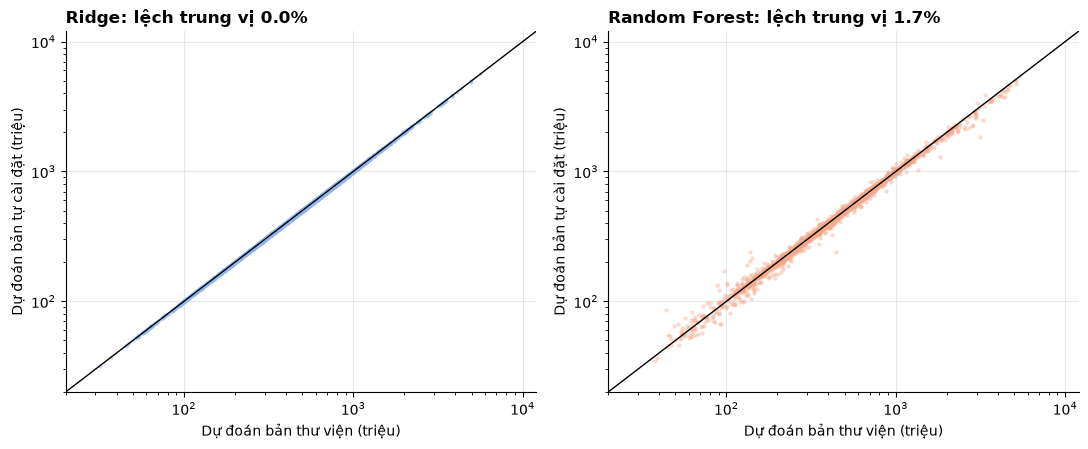

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (lib, own) in zip(axes, [("Ridge - thư viện", "Ridge - tự cài đặt (nghiệm đóng)"),
                                  ("Random Forest - thư viện", "Random Forest - tự cài đặt")]):
    ax.scatter(preds[lib], preds[own], s=5, alpha=0.3, color=COL[own])
    ax.plot(lim, lim, color="black", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
    diff = np.abs(preds[own] - preds[lib]) / preds[lib]
    ax.set_title(f"{lib.split(' -')[0]}: lệch trung vị {np.median(diff):.1%}", loc="left")
    ax.set_xlabel("Dự đoán bản thư viện (triệu)"); ax.set_ylabel("Dự đoán bản tự cài đặt (triệu)")
fig.tight_layout(); save(fig, "m11_tu_cai_dat_vs_thu_vien"); plt.show()

## 6. Diễn giải mô hình: đặc trưng nào quyết định giá?

### 6.1 Độ quan trọng đặc trưng (Random Forest)
Một đặc trưng phân loại bị one-hot thành nhiều cột (ví dụ hãng thành 28 cột). Để đọc đúng, **cộng độ quan trọng của mọi cột thuộc cùng một đặc trưng gốc**.

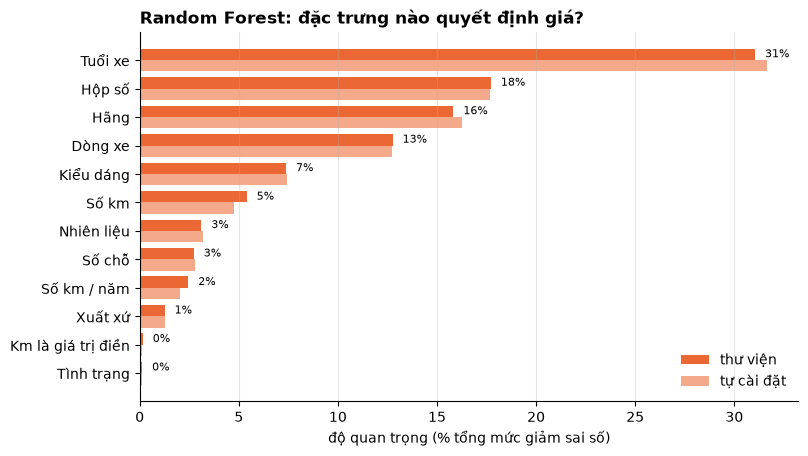

,thư viện,tự cài đặt
Tuổi xe,31.0,31.7
Hộp số,17.7,17.7
Hãng,15.8,16.3
Dòng xe,12.8,12.7
Kiểu dáng,7.4,7.4
Số km,5.4,4.7
Nhiên liệu,3.1,3.2
Số chỗ,2.7,2.8
Số km / năm,2.5,2.0
Xuất xứ,1.3,1.3


In [24]:
FEAT_VI = {"age": "Tuổi xe", "mileage_km": "Số km", "km_per_year": "Số km / năm", "carseats": "Số chỗ",
           "mileage_missing": "Km là giá trị điền", "carbrand_grp": "Hãng", "carmodel_grp": "Dòng xe",
           "carorigin": "Xuất xứ", "condition_ad": "Tình trạng", "gearbox": "Hộp số", "fuel": "Nhiên liệu",
           "cartype": "Kiểu dáng"}


def group_importance(imp, names):
    # Gộp độ quan trọng của các cột one-hot về đặc trưng gốc
    def origin(n):
        return next((c for c in CAT if n.startswith(c + "_")), n)
    return pd.Series(imp, index=[origin(n) for n in names]).groupby(level=0).sum().rename(FEAT_VI)


imp = pd.DataFrame({"thư viện": group_importance(rf_lib.feature_importances_, names_tree),
                    "tự cài đặt": group_importance(rf_s.feature_importances_, names_tree)}).sort_values("thư viện")

fig, ax = plt.subplots(figsize=(8.5, 4.8))
yy = np.arange(len(imp))
ax.barh(yy + 0.2, imp["thư viện"] * 100, 0.4, color=ORANGE, label="thư viện")
ax.barh(yy - 0.2, imp["tự cài đặt"] * 100, 0.4, color=LIGHT_ORANGE, label="tự cài đặt")
for i, v in enumerate(imp["thư viện"] * 100):
    ax.text(v + 0.5, i + 0.2, f"{v:.0f}%", va="center", fontsize=8)
ax.set_yticks(yy); ax.set_yticklabels(imp.index)
ax.set_xlabel("độ quan trọng (% tổng mức giảm sai số)")
ax.set_title("Random Forest: đặc trưng nào quyết định giá?", loc="left")
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="y", visible=False)
save(fig, "m12_do_quan_trong"); plt.show()
(imp.sort_values("thư viện", ascending=False) * 100).round(1)

**Đọc biểu đồ:**
- **Tuổi xe** quan trọng nhất (khoảng 1/3 tổng): khấu hao là yếu tố lớn nhất quyết định giá xe cũ.
- **Hãng và dòng xe** cộng lại gần ngang tuổi xe: hai chiếc cùng tuổi nhưng khác dòng (Vios và Land Cruiser) có thể chênh nhau hàng chục lần.
- **Hộp số** đứng thứ hai, cao hơn trực giác. Nhiều khả năng hộp số đóng vai trò **đại diện gián tiếp**: xe số sàn thường là xe đời cũ, xe tải nhẹ, xe phân khúc thấp, nên một câu hỏi "số sàn hay tự động?" tách được nhanh nhóm xe rẻ khỏi nhóm xe đắt. Độ quan trọng đo **mức đóng góp vào việc chia dữ liệu**, không phải tác động nhân quả của hộp số lên giá.
- **Tình trạng (mới/cũ)** gần như bằng 0 vì thông tin này đã nằm trong `tuổi xe = 0` và `số km = 0`. **Km là giá trị điền** cũng rất nhỏ: các xe được điền km không khác biệt về giá.
- Hai bản cài đặt cho **cùng thứ hạng** và gần như cùng tỉ lệ, thêm một bằng chứng cho thấy rừng tự viết hoạt động đúng.

### 6.2 Đường khấu hao: giá dự đoán theo tuổi xe
Lấy ba mẫu xe phổ biến ở ba phân khúc, cố định mọi thuộc tính, chỉ thay đổi **tuổi xe** (giả định chạy 15.000 km/năm; tuổi 0 là xe mới, 0 km), rồi xem hai mô hình dự đoán giá thế nào. Đây là cách trực quan để thấy mỗi mô hình "hiểu" về khấu hao ra sao.

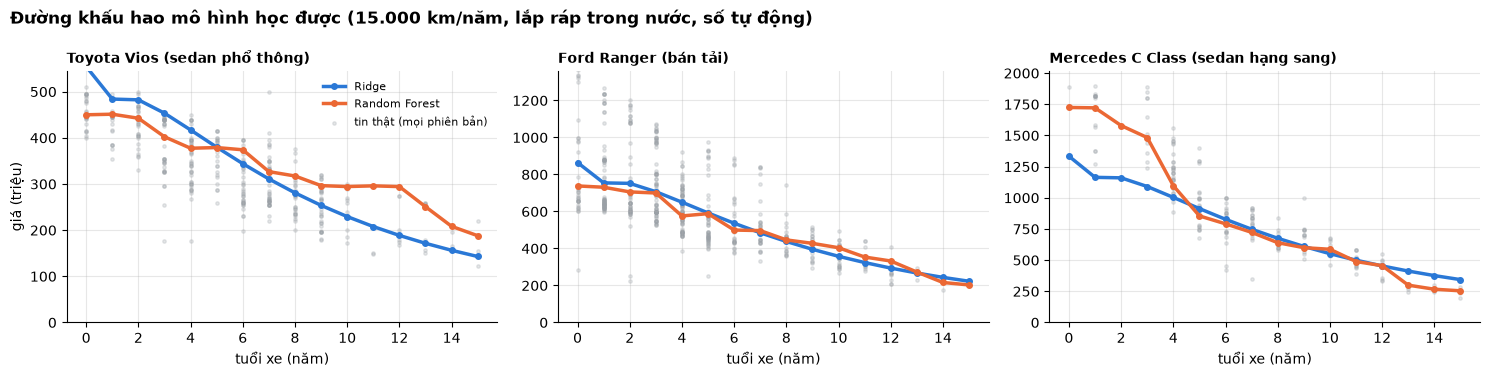

In [25]:
REF_CARS = {
    "Toyota Vios (sedan phổ thông)": dict(carbrand_grp="Toyota", carmodel_grp="Toyota Vios", cartype="Sedan", fuel="Xăng"),
    "Ford Ranger (bán tải)": dict(carbrand_grp="Ford", carmodel_grp="Ford Ranger", cartype="Pick-up (bán tải)", fuel="Dầu"),
    "Mercedes C Class (sedan hạng sang)": dict(carbrand_grp="Mercedes Benz", carmodel_grp="Mercedes Benz C Class",
                                               cartype="Sedan", fuel="Xăng"),
}
ages = np.arange(0, 16)


def depreciation_frame(spec):
    rows = []
    for a in ages:
        km = 15000.0 * a
        rows.append({**spec, "carorigin": "Việt Nam", "gearbox": "Tự động", "carseats": 5,
                     "condition_ad": "Mới" if a == 0 else "Đã sử dụng", "age": a, "age_sq": a * a,
                     "mileage_km": km, "km_per_year": km / max(a, 1), "mileage_missing": 0,
                     "log_km": np.log1p(km), "log_km_per_year": np.log1p(km / max(a, 1))})
    return pd.DataFrame(rows)


fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (title, spec) in zip(axes, REF_CARS.items()):
    f = depreciation_frame(spec)
    ax.plot(ages, np.exp(ridge_lib.predict(prep_lin.transform(f))), color=BLUE, lw=2.5, marker="o", ms=4, label="Ridge")
    ax.plot(ages, np.exp(rf_lib.predict(prep_tree.transform(f))), color=ORANGE, lw=2.5, marker="o", ms=4, label="Random Forest")
    real = df[(df["carmodel_grp"] == spec["carmodel_grp"]) & (df["age"] <= 15)]
    ax.scatter(real["age"], real["price_tr"], s=6, color=GRAY, alpha=0.25, label="tin thật (mọi phiên bản)")
    ax.set_title(title, loc="left", fontsize=10); ax.set_xlabel("tuổi xe (năm)")
    ax.set_ylim(0, real["price_tr"].quantile(0.98) * 1.1)
axes[0].set_ylabel("giá (triệu)"); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Đường khấu hao mô hình học được (15.000 km/năm, lắp ráp trong nước, số tự động)", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout(); save(fig, "m13_duong_khau_hao"); plt.show()

**Đọc biểu đồ:**
- **Ridge** cho đường khấu hao **trơn và cùng một hình dạng** cho mọi mẫu xe (chỉ dịch lên xuống theo mức giá của dòng xe), vì mô hình tuyến tính trên log giá giả định mọi xe mất giá **cùng một tỉ lệ %** mỗi năm.
- **Random Forest** cho đường dạng **bậc thang** (cây chia tuổi xe theo ngưỡng) và **hình dạng khác nhau giữa các dòng xe**: mô hình học được rằng mỗi phân khúc khấu hao theo cách riêng. Đây chính là **tương tác** giữa dòng xe và tuổi xe mà Ridge không biểu diễn được, và là lý do Random Forest chính xác hơn.
- Các điểm xám là tin thật của cùng dòng xe ở mọi phiên bản, mọi số km. Độ phân tán dọc lớn cho thấy phần giá mà dữ liệu không giải thích được (phiên bản, trang bị, tình trạng thực tế).

## 7. Thí nghiệm: log giá và các kỹ thuật xử lý mất cân bằng

Hai câu hỏi trả lời bằng số liệu, **trên chính mô hình cuối (Random Forest)**:
1. Học trên **log(giá)** có tốt hơn học trên giá gốc không?
2. Các kỹ thuật **xử lý mất cân bằng** có giúp phân khúc hiếm (xe trên 2 tỷ chỉ khoảng 3%) không?

**Mất cân bằng trong bài toán hồi quy** không có "lớp thiểu số" như phân loại, mà thể hiện ở **mật độ dữ liệu không đều theo vùng giá**: rất nhiều xe 200-1.000 triệu, rất ít xe trên 2 tỷ. Mô hình tối ưu sai số trung bình sẽ học tốt vùng đông và kém ở vùng thưa.

| Kỹ thuật | Cách làm (chỉ trong phần train của mỗi fold) |
|---|---|
| Không cân bằng | huấn luyện bình thường |
| **Trọng số mẫu** | mẫu ở phân khúc hiếm có trọng số lớn hơn: 1/√(tần suất phân khúc), chuẩn hóa về trung bình 1 |
| **Random Oversampling** | nhân bản ngẫu nhiên mẫu của phân khúc hiếm cho đến tối thiểu 25% quy mô phân khúc lớn nhất |
| **Random Undersampling** | bỏ bớt mẫu ở phân khúc đông, mỗi phân khúc giữ tối đa 8 lần số mẫu của phân khúc hiếm nhất |

**Cách đánh giá:** 5-fold CV phân tầng theo phân khúc giá **chỉ trên tập train**. Việc cân bằng chỉ áp dụng cho phần train của từng fold; phần validation **giữ nguyên phân phối thật**. Cân bằng trước khi chia sẽ làm bản sao của cùng một xe nằm ở cả hai phía và cho điểm cao giả tạo. **Tập test không được dùng ở mục này.**

In [26]:
def resample(tr_i, method, rng):
    # Vị trí các mẫu dùng để fit trong phần train của một fold (có thể lặp lại khi oversampling)
    s = seg_tr[tr_i]
    counts = pd.Series(s).value_counts()
    if method == "over":
        target = int(counts.max() * 0.25)
        extra = [rng.choice(tr_i[s == k], target - c, replace=True) for k, c in counts.items() if c < target]
        return np.concatenate([tr_i] + extra)
    if method == "under":
        cap = int(counts.min() * 8)
        return np.concatenate([rng.choice(tr_i[s == k], min(cap, c), replace=False) for k, c in counts.items()])
    return tr_i


def cv_oof(log_target=True, method=None):
    # Dự đoán out-of-fold (triệu đồng) trên tập train bằng Random Forest với tham số tốt nhất
    oof, sizes = np.zeros(len(y_tr)), []
    rng = np.random.RandomState(RANDOM_STATE)
    for tr_i, va_i in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(XT_tr, seg_tr):
        fit_i, w = resample(tr_i, method, rng), None
        if method == "weight":
            s = pd.Series(seg_tr[fit_i])
            w = (1 / np.sqrt(s.map(s.value_counts(normalize=True)))).values
            w = w / w.mean()
        m = RandomForestRegressor(**rs_rf.best_params_, random_state=RANDOM_STATE, n_jobs=-1)
        m.fit(XT_tr[fit_i], (y_tr if log_target else p_tr)[fit_i], sample_weight=w)
        pred = m.predict(XT_tr[va_i])
        oof[va_i] = np.exp(pred) if log_target else pred
        sizes.append(len(fit_i))
    return oof, int(np.mean(sizes))


variants = {"Giá gốc": (False, None), "Log giá": (True, None), "Log giá + trọng số mẫu": (True, "weight"),
            "Log giá + Oversampling": (True, "over"), "Log giá + Undersampling": (True, "under")}
exp_rows = {}
t0 = time.time()
for name, (log_target, method) in variants.items():
    oof, n_fit = cv_oof(log_target, method)
    met = regression_metrics(p_tr, oof)
    exp_rows[name] = {"cỡ train mỗi fold": n_fit, "MAPE": met["MAPE"], "MedAPE": met["MedAPE"],
                      "MAE (triệu)": met["MAE (triệu)"], **segment_mape(p_tr, oof, seg_tr)}
    print(f"{name:28s} MAPE (CV) = {met['MAPE']:.3f}  ({time.time() - t0:.0f}s)")
exp_res = pd.DataFrame(exp_rows).T
exp_res.round(3)

Giá gốc                      MAPE (CV) = 0.196  (51s)


Log giá                      MAPE (CV) = 0.162  (93s)


Log giá + trọng số mẫu       MAPE (CV) = 0.163  (124s)


Log giá + Oversampling       MAPE (CV) = 0.161  (162s)


Log giá + Undersampling      MAPE (CV) = 0.168  (185s)


,cỡ train mỗi fold,MAPE,MedAPE,MAE (triệu),MAPE < 200 triệu,MAPE 200-500,MAPE 500-1.000,MAPE 1-2 tỷ,MAPE > 2 tỷ
Giá gốc,8919.0,0.196,0.097,100.019,0.513,0.158,0.115,0.156,0.225
Log giá,8919.0,0.162,0.091,100.146,0.357,0.128,0.108,0.165,0.274
Log giá + trọng số mẫu,8919.0,0.163,0.088,96.398,0.349,0.136,0.112,0.153,0.241
Log giá + Oversampling,9830.0,0.161,0.087,96.357,0.360,0.128,0.110,0.163,0.245
Log giá + Undersampling,6925.0,0.168,0.095,101.446,0.355,0.143,0.110,0.160,0.267


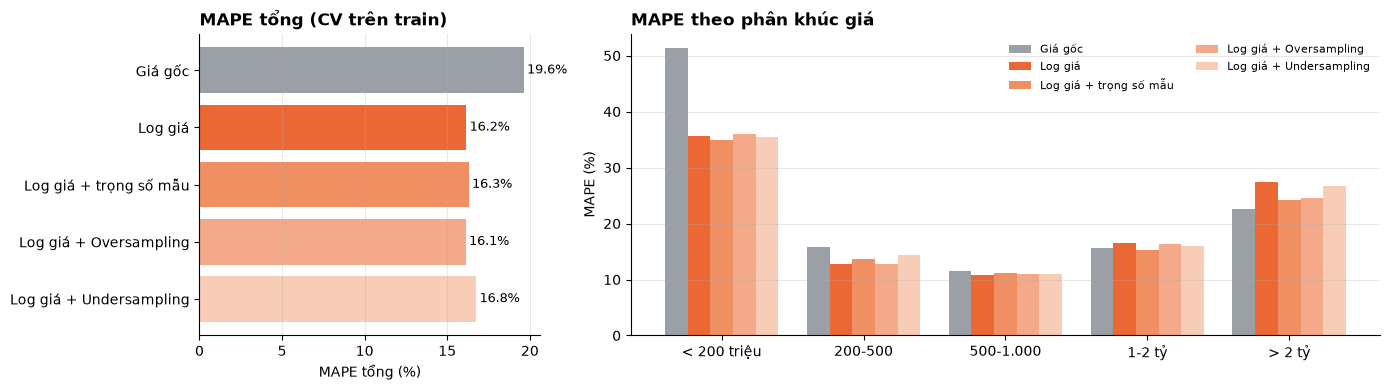

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 2.2]})
exp_colors = [GRAY, ORANGE, "#f08f62", LIGHT_ORANGE, "#f8cdb8"]
v = exp_res["MAPE"] * 100
axes[0].barh(exp_res.index[::-1], v[::-1], color=exp_colors[::-1])
for i, val in enumerate(v[::-1]):
    axes[0].text(val + 0.2, i, f"{val:.1f}%", va="center", fontsize=9)
axes[0].set_xlabel("MAPE tổng (%)"); axes[0].set_title("MAPE tổng (CV trên train)", loc="left")
axes[0].grid(axis="y", visible=False)

w = 0.8 / len(exp_res)
for k, (name, col) in enumerate(zip(exp_res.index, exp_colors)):
    axes[1].bar(np.arange(len(SEG_LABELS)) + (k - 2) * w, exp_res.loc[name, seg_cols].astype(float) * 100, w,
                color=col, label=name)
axes[1].set_xticks(np.arange(len(SEG_LABELS))); axes[1].set_xticklabels(SEG_LABELS)
axes[1].set_ylabel("MAPE (%)"); axes[1].set_title("MAPE theo phân khúc giá", loc="left")
axes[1].legend(frameon=False, fontsize=8, ncol=2); axes[1].grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "m14_log_va_mat_can_bang"); plt.show()

### 7.1 Kết luận thí nghiệm
**1. Log giá tốt hơn rõ rệt.** MAPE tổng giảm từ khoảng 19,6% (giá gốc) xuống 16,2% (log giá); phân khúc dưới 200 triệu cải thiện mạnh nhất (khoảng 51% → 36%). Học trên giá gốc thì sai số bình phương bị xe đắt chi phối, nên mô hình bỏ qua sai số tương đối ở xe rẻ. Đổi lại, giá gốc tốt hơn ở xe trên 2 tỷ (khoảng 22% so với 27%), cũng vì lý do đó. Với thước đo chính là MAPE, **chọn log giá**.

**2. Các kỹ thuật cân bằng không thay đổi MAPE tổng, nhưng giúp phân khúc hiếm:**
- **MAPE tổng** của ba kỹ thuật nằm trong khoảng 16,1-16,8%, so với 16,2% khi không cân bằng. Chênh lệch dưới 1 điểm %, trong mức dao động thông thường của cross-validation.
- **Oversampling** và **trọng số mẫu** giảm sai số ở **xe trên 2 tỷ** khoảng 3 điểm % (27,4% → 24-25%) vì mô hình "nhìn thấy" xe sang nhiều hơn khi học. Trọng số mẫu phải đổi lại bằng sai số cao hơn ở phân khúc đông nhất 200-500 triệu (12,8% → 13,6%); oversampling gần như không làm phân khúc nào kém đi.
- **Undersampling** bỏ đi khoảng 22% dữ liệu train, MAPE tổng tăng (16,8%) và gần như không giúp xe sang: bỏ dữ liệu thật thì mất thông tin.
- **Giới hạn của cân bằng dữ liệu:** dù đã cân bằng, sai số ở xe trên 2 tỷ vẫn cao hơn gấp đôi phân khúc giữa. Nguyên nhân chủ yếu là **thiếu thông tin** (phiên bản, trang bị quyết định giá xe sang), chứ không chỉ do ít mẫu. Nhân bản dữ liệu không tạo thêm thông tin mới.

**Quyết định:** mô hình cuối **học trên log giá, không dùng kỹ thuật cân bằng**, vì thước đo chính (MAPE trên toàn thị trường) không đổi, và mô hình đơn giản hơn. **Nếu ứng dụng ưu tiên định giá xe sang, nên dùng Random Oversampling** (chỉ trên tập train): sai số ở xe trên 2 tỷ giảm khoảng 3 điểm % mà các phân khúc khác gần như không bị ảnh hưởng. Mọi quyết định ở đây chỉ dựa trên CV trên tập train.

## 8. Hạn chế: ảnh hưởng của tin đăng lại

`preprocess_data.ipynb` đã xóa các tin **trùng hoàn toàn** (cùng mọi thuộc tính và cùng giá). Tuy nhiên cùng một chiếc xe có thể được **đăng lại với giá chênh nhẹ**, nên vẫn còn ở dạng hai dòng gần giống nhau. Khi chia ngẫu nhiên, một bản rơi vào train và bản kia vào test; Random Forest với lá nhỏ chỉ cần "nhớ" giá là đoán đúng.

**Kiểm tra:** dòng test nào có một dòng train **giống hệt mọi đặc trưng, kể cả số km**? Với xe đã dùng, trùng cả số km gần như chắc chắn là cùng một xe. Với xe mới (0 km), đó có thể là nhiều xe cùng cấu hình của đại lý.

In [28]:
FEAT_KEY = ["carbrand", "carmodel", "carorigin", "condition_ad", "gearbox", "fuel", "cartype", "carseats", "mfdate", "mileage_km"]
key = df[FEAT_KEY].astype(str).agg("|".join, axis=1)
twin = key.loc[idx_te].isin(set(key.loc[idx_tr])).values
used_te = (te["condition_ad"] == "Đã sử dụng").values

groups = {"có bản sao trong train": twin, "  trong đó xe đã dùng": twin & used_te,
          "không có bản sao": ~twin, "toàn bộ test": np.ones(len(twin), bool)}
rows = {}
for g, msk in groups.items():
    rows[g] = {"số tin": int(msk.sum()), "% test": msk.mean() * 100}
    for n in ["Ridge - thư viện", "Random Forest - thư viện"]:
        rows[g][f"MAPE {SHORT[n]}"] = (np.abs(preds[n] - p_te) / p_te)[msk].mean()
twin_tbl = pd.DataFrame(rows).T
twin_tbl.round(3)

,số tin,% test,MAPE Ridge (thư viện),MAPE RF (thư viện)
có bản sao trong train,391.0,14.024,0.140,0.109
trong đó xe đã dùng,247.0,8.859,0.140,0.105
không có bản sao,2397.0,85.976,0.192,0.162
toàn bộ test,2788.0,100.000,0.185,0.155


**Nhận xét:** trên các tin có "bản sao" trong train, sai số thấp hơn hẳn, nhất là với Random Forest (mô hình "nhớ" được giá của chính chiếc xe đó). Vì vậy **MAPE trên nhóm không có bản sao là ước lượng thận trọng hơn** cho một chiếc xe hoàn toàn mới với mô hình. Notebook giữ cách chia ngẫu nhiên có phân tầng để thống nhất với các mục trên, và nêu điều này như một **hạn chế**. Cách chặt chẽ hơn là chia theo nhóm (`StratifiedGroupKFold`) để mọi bản đăng của một xe nằm cùng một phía.

## 9. Xuất mô hình

Lưu các mô hình đã huấn luyện vào thư mục `model/` (cạnh `src/`) để dùng lại mà không phải huấn luyện lại:

| File | Nội dung |
|---|---|
| `preprocessor_ridge.joblib`, `preprocessor_rf.joblib` | bộ mã hóa one-hot + chuẩn hóa của từng mô hình (đã fit trên train) |
| `ridge_sklearn.joblib`, `random_forest_sklearn.joblib` | mô hình thư viện |
| `ridge_scratch.npz` | vector trọng số của Ridge tự cài đặt (nghiệm đóng) |
| `random_forest_scratch.npz` | các cây và ngưỡng bin của rừng tự cài đặt, lưu dạng mảng NumPy (không phụ thuộc định nghĩa lớp trong notebook) |
| `metadata.json` | danh sách đặc trưng, bảng gộp nhãn hãng/dòng xe, trung vị số km theo năm, tham số tốt nhất, metric trên test |
| `price_model.py` | hàm `load_model` / `predict_price`: nhận thông tin thô của xe, tự dựng đặc trưng như lúc huấn luyện |
| `*.pkl` | (tùy chọn) mỗi mô hình kèm bộ tiền xử lý trong một file, tạo bằng `python export_pkl.py` |

In [29]:
import joblib, sklearn

MODEL_DIR = Path("../model")
MODEL_DIR.mkdir(exist_ok=True)
(MODEL_DIR / "preprocessor.joblib").unlink(missing_ok=True)          # file của phiên bản cũ (một bộ tiền xử lý chung)

joblib.dump(prep_lin, MODEL_DIR / "preprocessor_ridge.joblib", compress=3)
joblib.dump(prep_tree, MODEL_DIR / "preprocessor_rf.joblib", compress=3)
joblib.dump(ridge_lib, MODEL_DIR / "ridge_sklearn.joblib", compress=3)
joblib.dump(rf_lib, MODEL_DIR / "random_forest_sklearn.joblib", compress=3)
np.savez_compressed(MODEL_DIR / "ridge_scratch.npz", w=ridge_closed.w_)

edges = rf_s.binner_.edges_
payload = {"n_trees": len(rf_s.trees_), "edges": np.concatenate(edges),
           "edge_offsets": np.cumsum([0] + [len(e) for e in edges])}
for i, t in enumerate(rf_s.trees_):
    payload.update({f"t{i}_feature": t.feature_, f"t{i}_thr": t.thr_, f"t{i}_left": t.left_,
                    f"t{i}_right": t.right_, f"t{i}_value": t.value_})
np.savez_compressed(MODEL_DIR / "random_forest_scratch.npz", **payload)

used = df["condition_ad"] == "Đã sử dụng"
km_med = df[used & (df["mileage_missing"] == 0)].groupby("mfdate")["mileage_km"].median()
metadata = {
    "target": "ln(giá triệu đồng); dự đoán xong dùng exp() để ra triệu đồng",
    "current_year": 2026,
    "cat_features": CAT, "num_features_ridge": NUM_LIN, "num_features_rf": NUM_TREE,
    # bảng gộp nhãn học từ dữ liệu huấn luyện (giống preprocess_data.ipynb mục 7.2)
    "brand_group": df.groupby("carbrand")["carbrand_grp"].first().to_dict(),
    "model_group": (df.assign(full=df["carbrand"] + " " + df["carmodel"]).groupby("full")["carmodel_grp"].first().to_dict()),
    "luxury_brands": ["Bentley", "Rolls Royce", "Maybach", "Aston Martin", "Ferrari", "Lamborghini", "McLaren",
                      "Maserati", "Cadillac", "Lincoln", "Hummer", "Jaguar", "Infiniti", "Acura", "Volvo",
                      "Alfa Romeo", "MINI", "Jeep", "Genesis", "Lotus"],
    "mileage_median_by_year": {int(k): float(v) for k, v in km_med.items()},
    "mileage_median_all": float(df.loc[used & (df["mileage_missing"] == 0), "mileage_km"].median()),
    "categories": {c: sorted(df[c].unique().tolist()) for c in ["carorigin", "condition_ad", "gearbox", "fuel", "cartype"]},
    "best_params": {"ridge_alpha_sklearn_scale": float(best_alpha_lib),
                    "random_forest_sklearn": rs_rf.best_params_,
                    "random_forest_scratch": {**best_cfg, "n_estimators": N_TREES}},
    "test_metrics": {k: {m: round(float(v), 4) for m, v in r.items()} for k, r in results.items()},
    "sklearn_version": sklearn.__version__, "n_train": int(len(tr)), "random_state": RANDOM_STATE,
}
with open(MODEL_DIR / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2, default=int)

pd.Series({p.name: p.stat().st_size / 1e6 for p in sorted(MODEL_DIR.iterdir())
           if p.is_file() and p.suffix in {".joblib", ".npz", ".json", ".py"}}).round(2).to_frame("MB")

,MB
export_pkl.py,0.00
metadata.json,0.03
preprocessor_rf.joblib,0.00
preprocessor_ridge.joblib,0.00
price_model.py,0.01
random_forest_scratch.npz,6.24
random_forest_sklearn.joblib,48.85
ridge_scratch.npz,0.00
ridge_sklearn.joblib,0.00


**Kiểm tra:** nạp lại mô hình bằng `price_model.py`, truyền vào **thông tin thô** của các xe trong tập test (hãng, dòng xe gốc, năm sản xuất, số km...), để module tự dựng đặc trưng như lúc huấn luyện. Dự đoán phải trùng khớp với dự đoán trong notebook.

In [30]:
sys.path.insert(0, str(MODEL_DIR))
import importlib, price_model
importlib.reload(price_model)

name_map = {"ridge_sklearn": "Ridge - thư viện", "ridge_scratch": "Ridge - tự cài đặt (nghiệm đóng)",
            "random_forest_sklearn": "Random Forest - thư viện", "random_forest_scratch": "Random Forest - tự cài đặt"}
raw_test = te[["carbrand", "carmodel", "carorigin", "condition_ad", "gearbox", "fuel", "cartype", "carseats",
               "mfdate", "mileage_km", "mileage_missing"]]
for key, label in name_map.items():
    p_loaded = price_model.predict_price(price_model.load_model(key), raw_test)
    print(f"{key:24s} lệch lớn nhất so với notebook = {np.abs(p_loaded - preds[label]).max():.1e} triệu")
    assert np.allclose(p_loaded, preds[label], rtol=1e-9, atol=1e-6)

demo = pd.DataFrame([
    {"carbrand": "Toyota", "carmodel": "Vios", "carorigin": "Việt Nam", "condition_ad": "Đã sử dụng", "gearbox": "Tự động",
     "fuel": "Xăng", "cartype": "Sedan", "carseats": 5, "mfdate": 2018, "mileage_km": 80000},
    {"carbrand": "Ford", "carmodel": "Ranger", "carorigin": "Thái Lan", "condition_ad": "Đã sử dụng", "gearbox": "Tự động",
     "fuel": "Dầu", "cartype": "Pick-up (bán tải)", "carseats": 5, "mfdate": 2021, "mileage_km": None},
])
out = pd.DataFrame({k: price_model.predict_price(price_model.load_model(k), demo) for k in name_map},
                   index=["Toyota Vios 2018, 80.000 km", "Ford Ranger 2021, không rõ km"]).round(0)
out

ridge_sklearn            lệch lớn nhất so với notebook = 0.0e+00 triệu
ridge_scratch            lệch lớn nhất so với notebook = 6.4e-12 triệu


random_forest_sklearn    lệch lớn nhất so với notebook = 1.6e-11 triệu


random_forest_scratch    lệch lớn nhất so với notebook = 0.0e+00 triệu


,ridge_sklearn,ridge_scratch,random_forest_sklearn,random_forest_scratch
"Toyota Vios 2018, 80.000 km",281.0,281.0,303.0,303.0
"Ford Ranger 2021, không rõ km",596.0,596.0,515.0,536.0


## 10. Kết luận

Số liệu lấy từ lần chạy với `random_state = 42` (train 11.149 tin, test 2.788 tin).

### 10.1 Kết quả chính trên tập test

| Mô hình | MAPE | MedAPE | R² (log) | Lệch ≤ 10% | Lệch ≤ 20% | Thời gian huấn luyện |
|---|---|---|---|---|---|---|
| Baseline (luôn đoán trung vị) | 83,5% | 40,0% | 0,00 | 14% | 26% | - |
| Ridge (thư viện / tự cài đặt) | 18,5% | 10,7% | 0,873 | 48% | 75% | 0,03 giây |
| **Random Forest (thư viện)** | **15,5%** | **9,0%** | **0,891** | 54% | **80%** | 9 giây |
| Random Forest (tự cài đặt) | 15,7% | 9,0% | 0,887 | 55% | 80% | 2 phút |

**1. Cả hai mô hình đều vượt xa mốc so sánh.** Baseline sai trung bình 83,5%; Ridge giảm còn 18,5%, Random Forest còn 15,5%. Với Random Forest, **4 trên 5 xe** được định giá lệch không quá 20%, và sai số điển hình (MedAPE) khoảng 9%.

**2. Random Forest tốt hơn Ridge, và chênh lệch có ý nghĩa thống kê.** MAPE thấp hơn khoảng 3 điểm % (khoảng tin cậy 95% của hiệu: 2,1 đến 4,0 điểm), tốt hơn ở mọi phân khúc giá. Lý do: giá xe phụ thuộc **phi tuyến** và có **tương tác**. Đường khấu hao ở mục 6.2 cho thấy rõ: Ridge buộc mọi dòng xe mất giá cùng một tỉ lệ mỗi năm, còn Random Forest học được rằng xe sang (Mercedes C Class) mất giá rất nhanh trong 3-4 năm đầu, khác hẳn xe phổ thông.

**3. Ridge vẫn có giá trị riêng:** huấn luyện gần như tức thì, và **giải thích được** từng thuộc tính làm giá tăng/giảm bao nhiêu % (mục 3.4). Mức chênh 3 điểm % chính là phần đóng góp của quan hệ phi tuyến và tương tác mà mô hình tuyến tính bỏ lỡ.

### 10.2 Sai số theo phân khúc giá

| Phân khúc | % dữ liệu | Ridge | Random Forest |
|---|---|---|---|
| < 200 triệu | 14% | 43,0% | 34,7% |
| 200-500 triệu | 42% | 13,9% | 11,7% |
| 500-1.000 triệu | 33% | 12,6% | 10,9% |
| 1-2 tỷ | 8% | 16,7% | 15,7% |
| > 2 tỷ | 3% | 34,3% | 27,0% |

- **Phân khúc giữa (200 triệu - 1 tỷ, khoảng 75% thị trường):** sai số khoảng 11%, đủ tốt để tham khảo giá.
- **Xe dưới 200 triệu:** sai số phần trăm cao vì giá thấp: chênh vài chục triệu (tình trạng thực tế, thương lượng) đã là phần trăm lớn. Xe đời cũ rất khác nhau về tình trạng mà dữ liệu không có. Có thể vẫn còn tin ghi tiền trả trước mà bước tiền xử lý chưa bắt được.
- **Xe trên 2 tỷ:** chỉ 3% dữ liệu và thiếu thông tin quyết định giá xe sang (phiên bản, trang bị).

### 10.3 Bản tự cài đặt
- **Ridge:** nghiệm đóng tự viết trùng `sklearn` đến sai số làm tròn của máy tính (hệ số lệch khoảng 1e-11); gradient descent hội tụ về cùng nghiệm; K-fold tự viết chọn đúng cùng `alpha` với `GridSearchCV`.
- **Cây quyết định:** với cùng tham số, cây tự viết có số nút và R² gần như bằng cây của `sklearn`.
- **Random Forest:** MAPE 15,7% so với 15,5%; chênh lệch **không có ý nghĩa thống kê** (khoảng tin cậy của hiệu chứa 0). OOB R² 0,892 so với 0,896, và hai bản cho cùng thứ hạng đặc trưng quan trọng. Chênh lệch nhỏ đến từ việc chia đặc trưng thành 32 bin và rừng tự viết dùng 100 cây thay vì 300.
- **Chi phí tính toán** là khác biệt lớn nhất: rừng tự viết bằng Python mất khoảng 2 phút, bản thư viện khoảng 9 giây (viết bằng C/Cython, chạy song song nhiều lõi). Gradient descent của Ridge mất khoảng 23 giây so với một phần trăm giây của nghiệm đóng.

### 10.4 Các quyết định đã kiểm chứng bằng dữ liệu (CV trên tập train)
- **Học trên log giá:** MAPE 16,2% so với 19,6% khi học trên giá gốc.
- **Xử lý mất cân bằng:** trọng số mẫu và oversampling giữ nguyên MAPE tổng nhưng giảm khoảng 3 điểm % sai số ở xe trên 2 tỷ; undersampling làm kết quả kém đi. Mô hình cuối không cân bằng; oversampling là lựa chọn nếu ưu tiên xe sang (mục 7).
- **Yếu tố quyết định giá:** tuổi xe (khoảng 31%), hộp số (18%), hãng (16%), dòng xe (13%), kiểu dáng (7%).

### 10.5 Hạn chế và hướng phát triển
- **Giá rao bán, không phải giá giao dịch:** luôn có phần thương lượng mà mô hình không biết.
- **Tin đăng lại:** khoảng 14% tin test có một tin trong train giống hệt mọi đặc trưng kể cả số km. Trên nhóm không có bản sao, MAPE của Random Forest là 16,2% (so với 15,5% trên toàn bộ test), nên con số 15,5% hơi lạc quan. Cách chặt chẽ hơn là chia train/test theo nhóm.
- **Thiếu đặc trưng quan trọng:** phiên bản/trang bị, tình trạng thân vỏ và nội thất, số đời chủ. Crawl thêm phần mô tả tin đăng có thể bổ sung các thông tin này.
- **Giá dự đoán** là `exp()` của dự đoán log giá, tức ước lượng **trung vị** của giá, hơi thấp hơn giá trung bình; phù hợp với MAPE nên không hiệu chỉnh.
- **Hướng mở rộng mô hình:** Gradient Boosting (học tuần tự các cây sửa lỗi của nhau) có thể dùng lại lớp cây đã tự cài đặt; thử hàm mất mát theo phần trăm để cải thiện hai đầu thang giá.